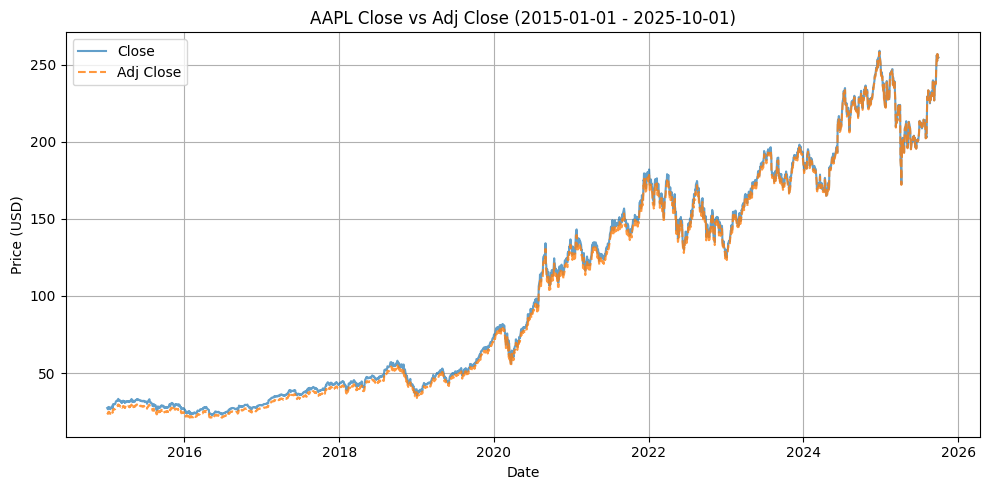

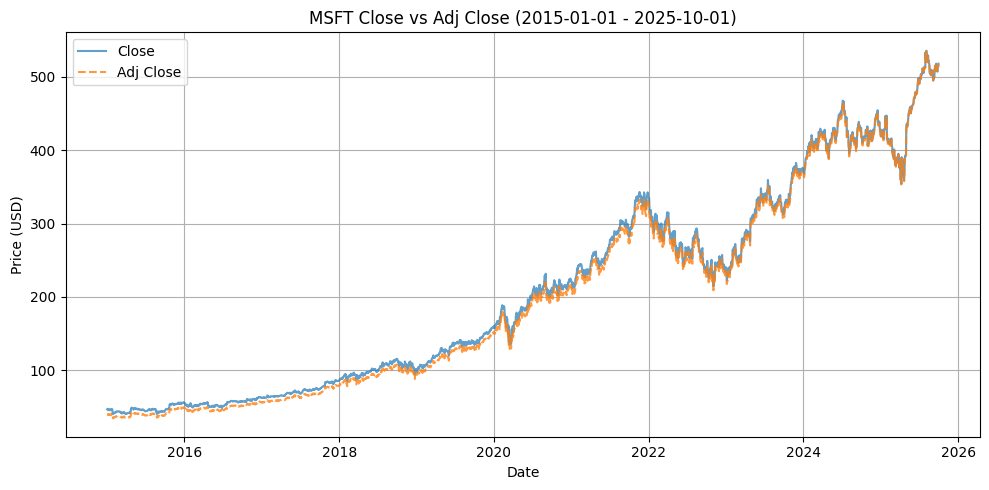

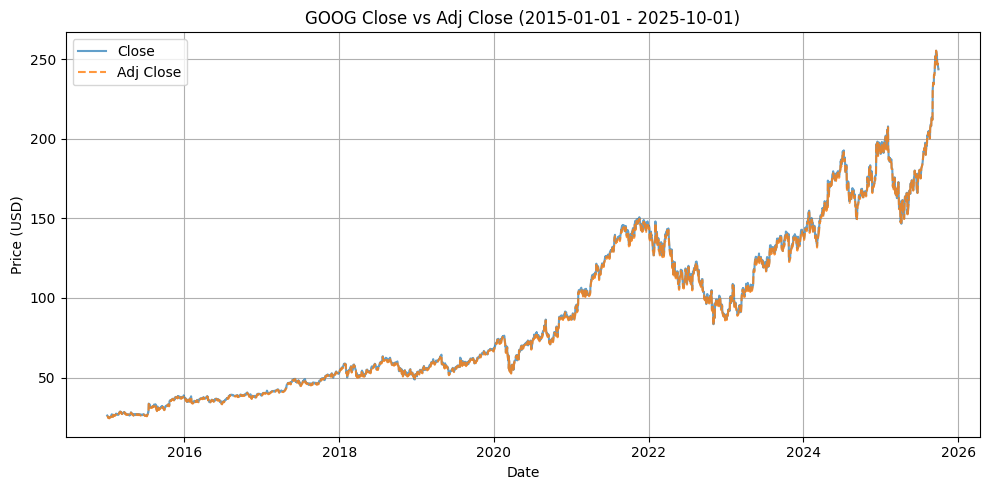

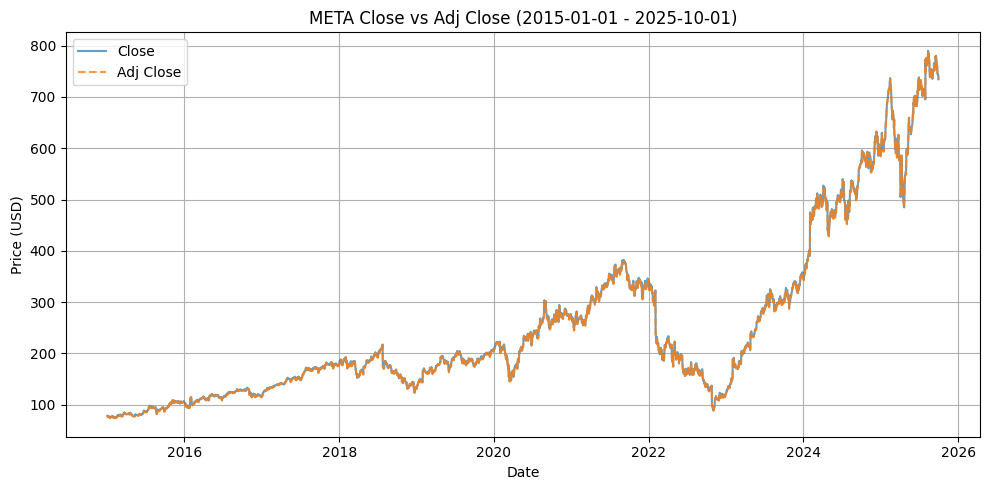

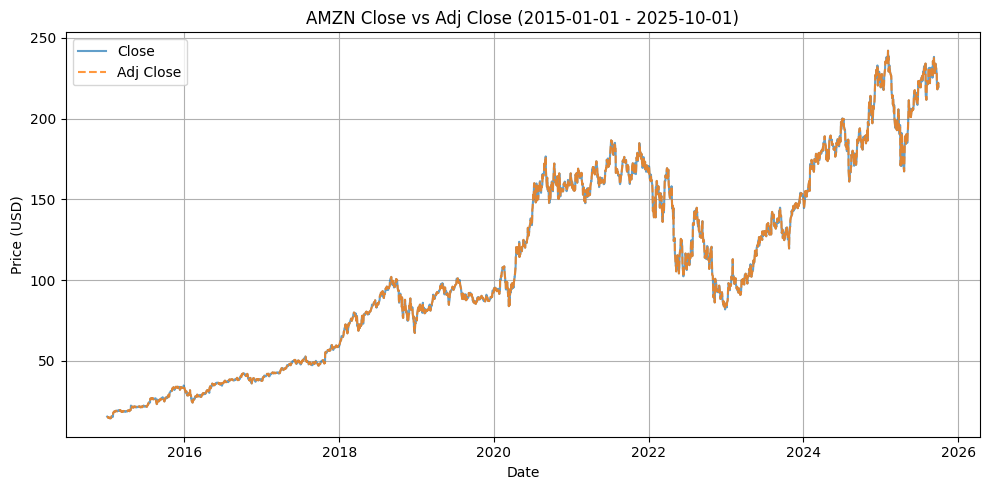

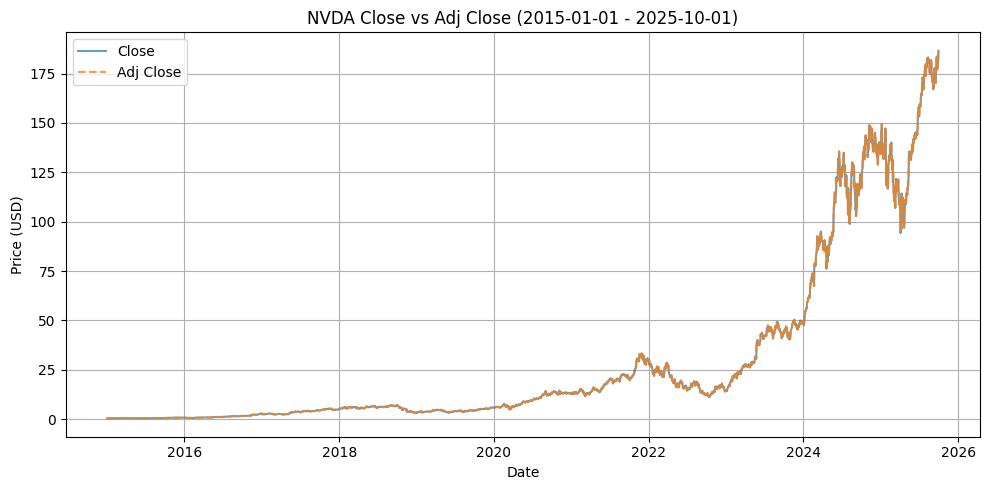

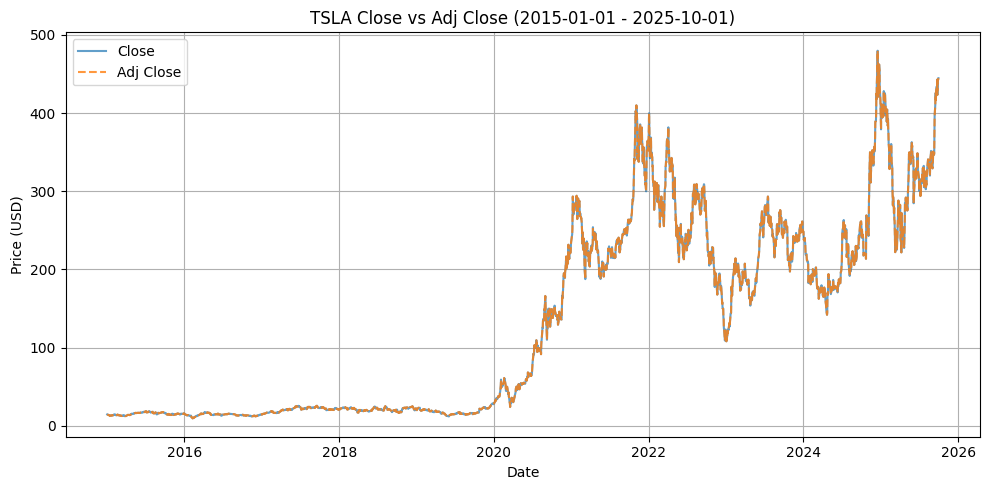

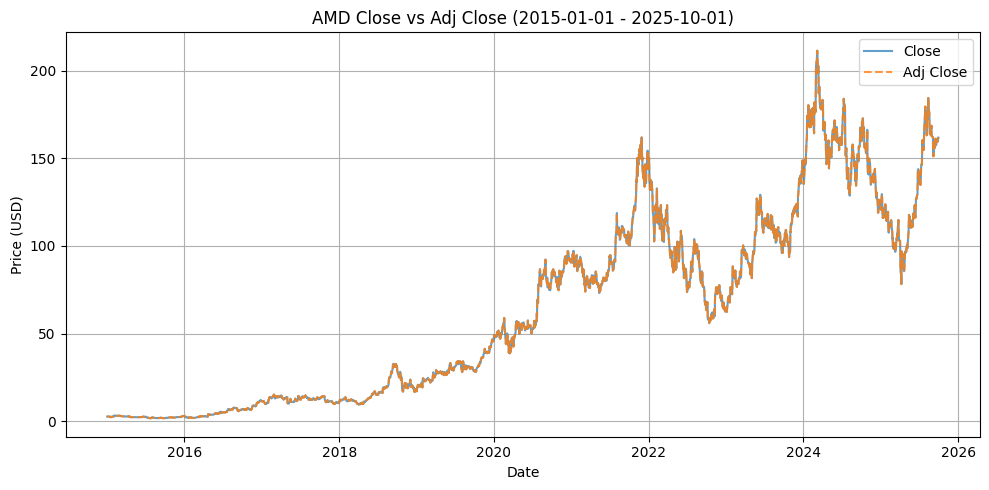

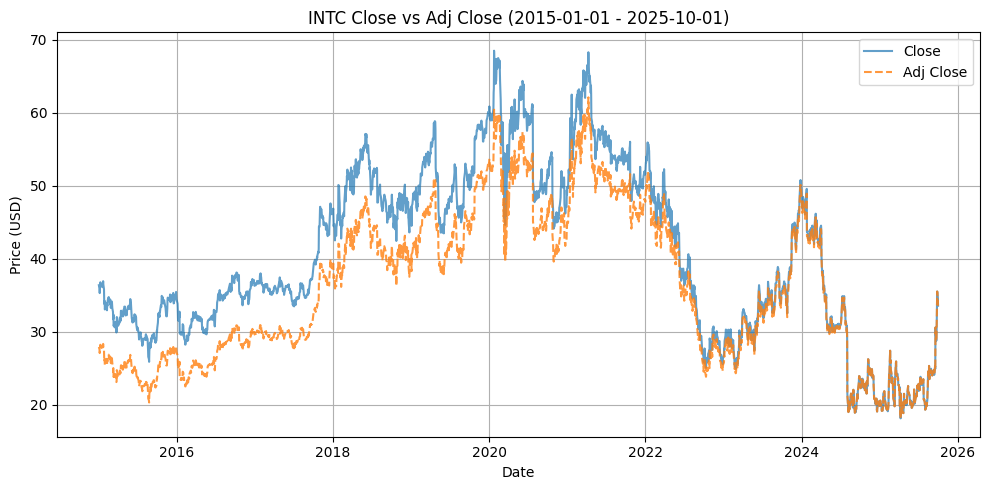

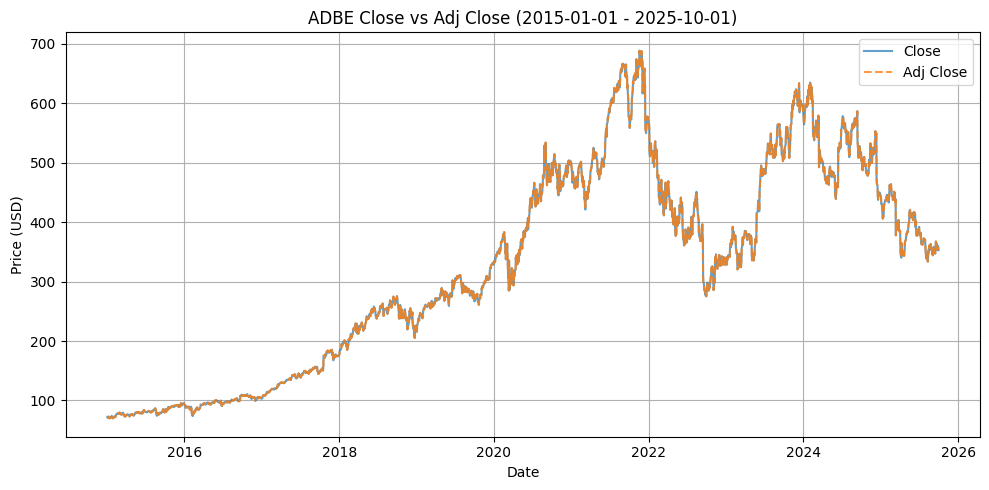

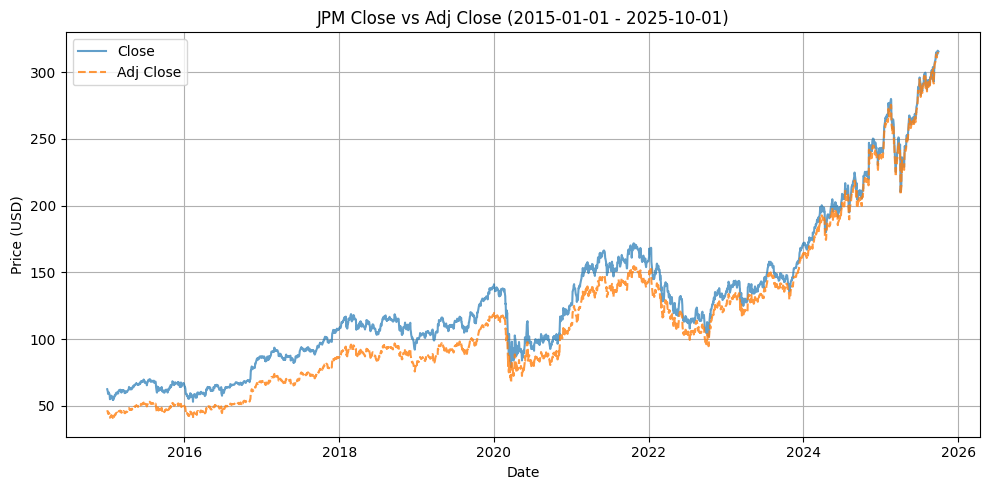

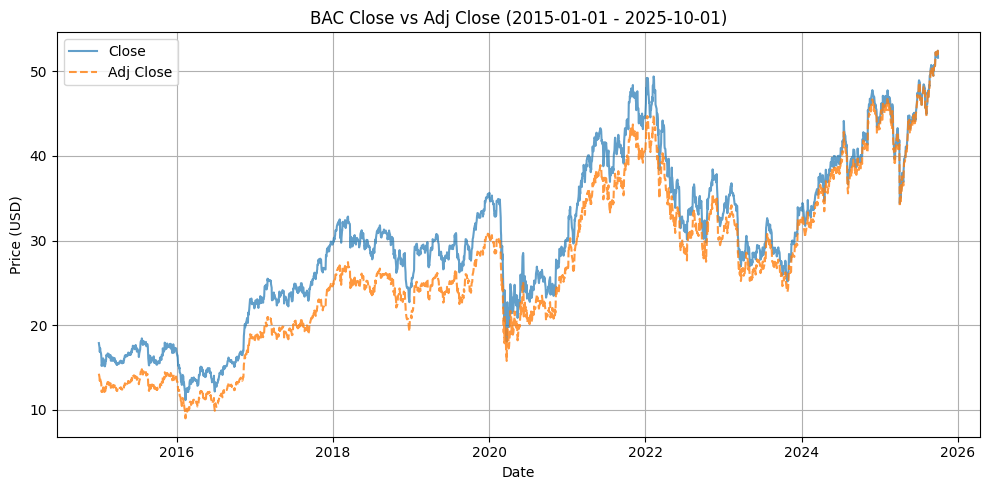

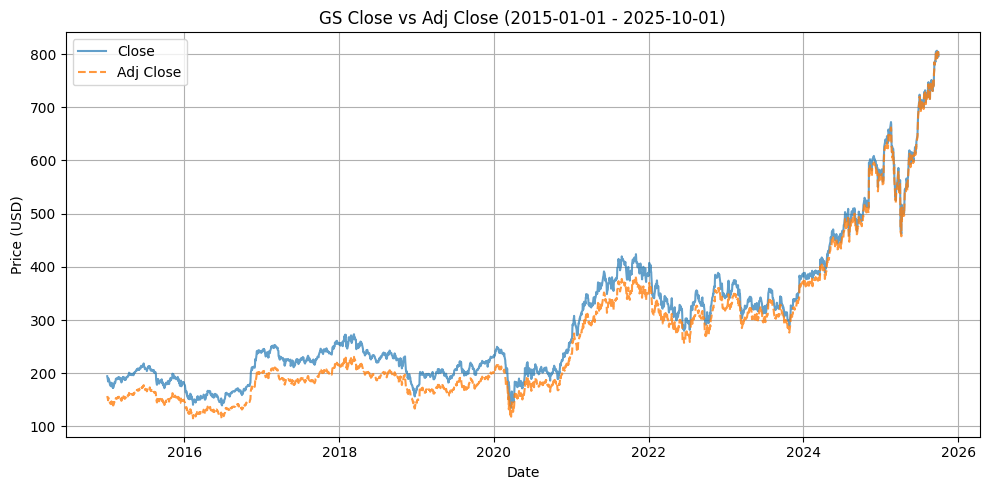

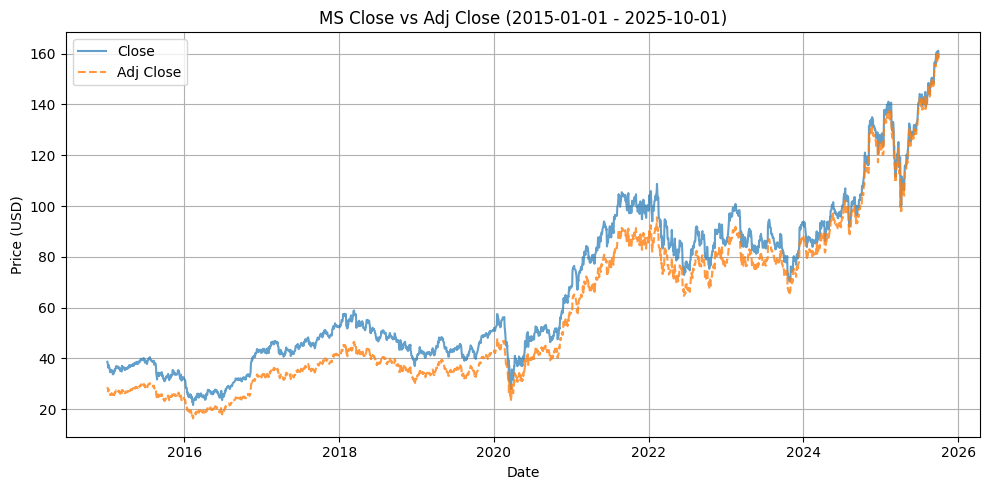

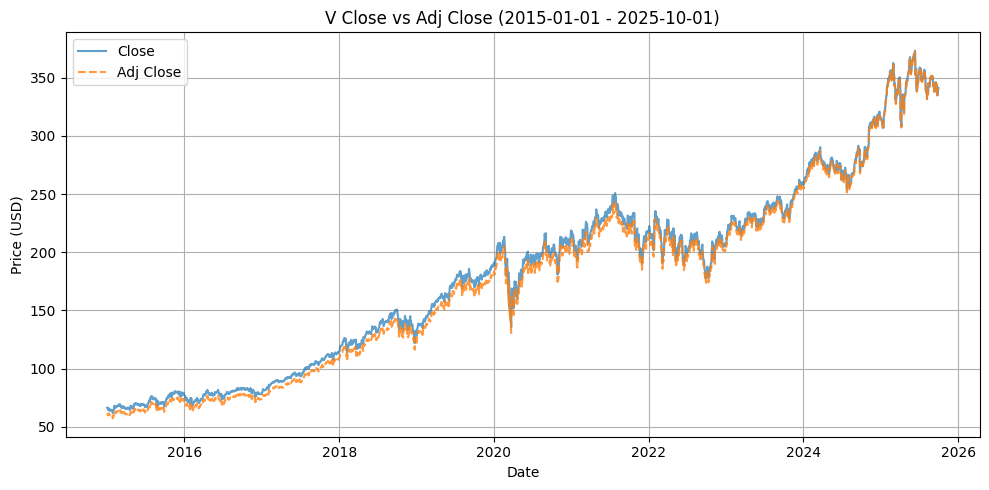

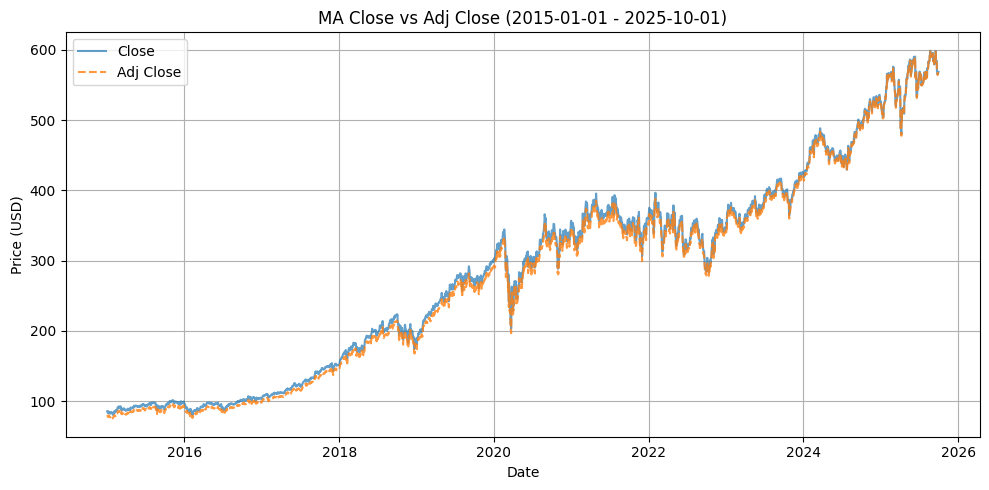

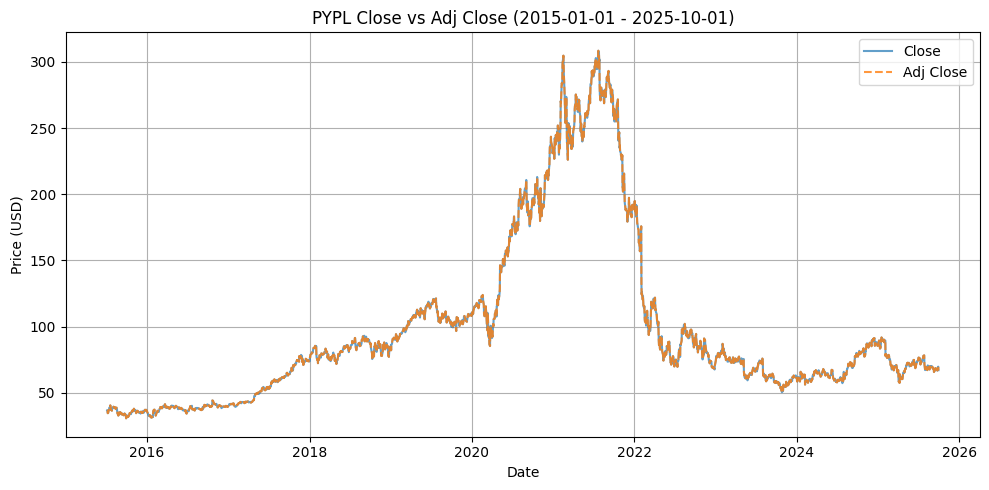

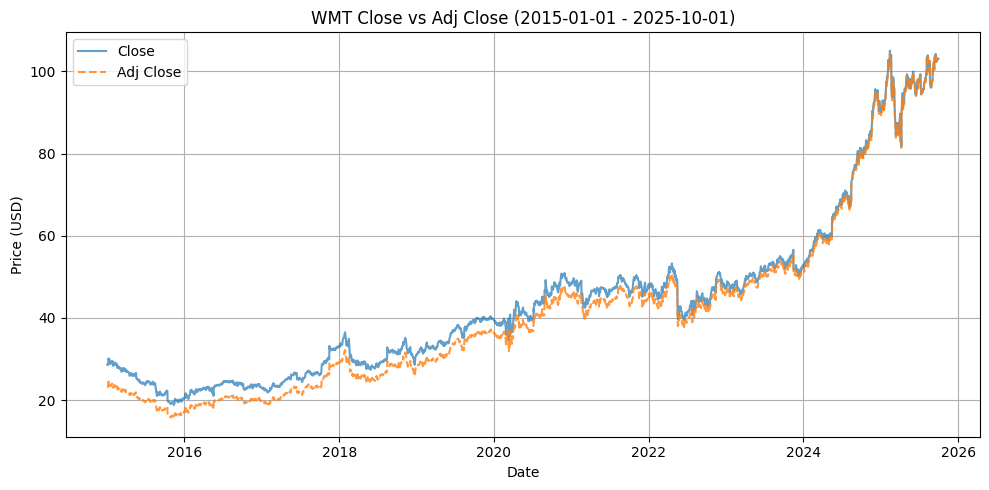

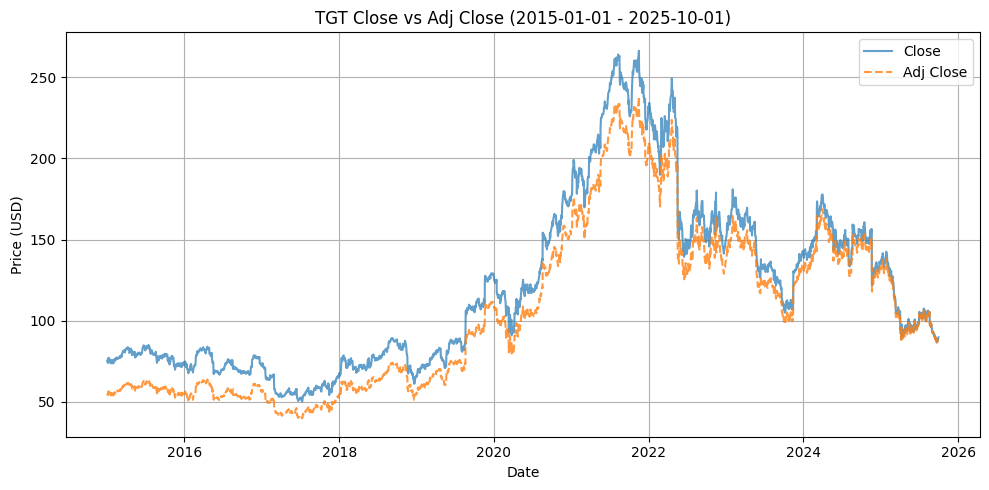

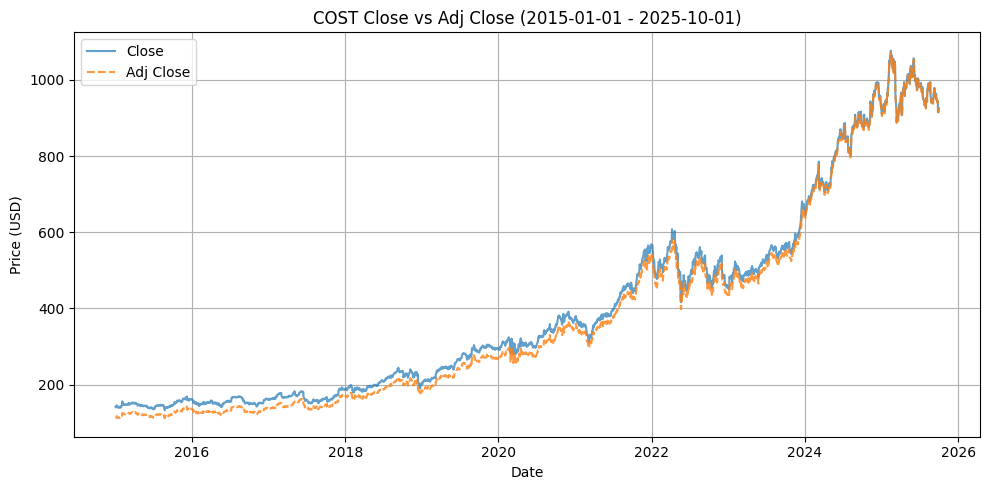

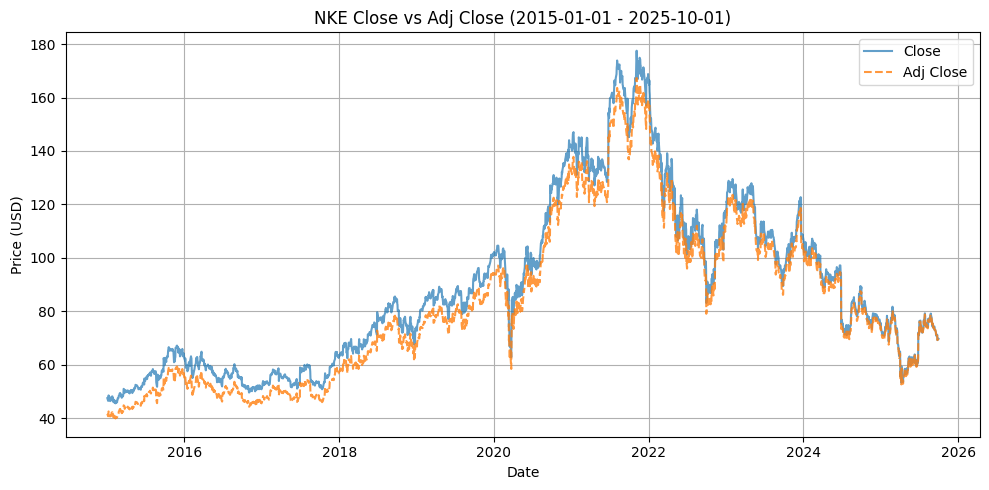

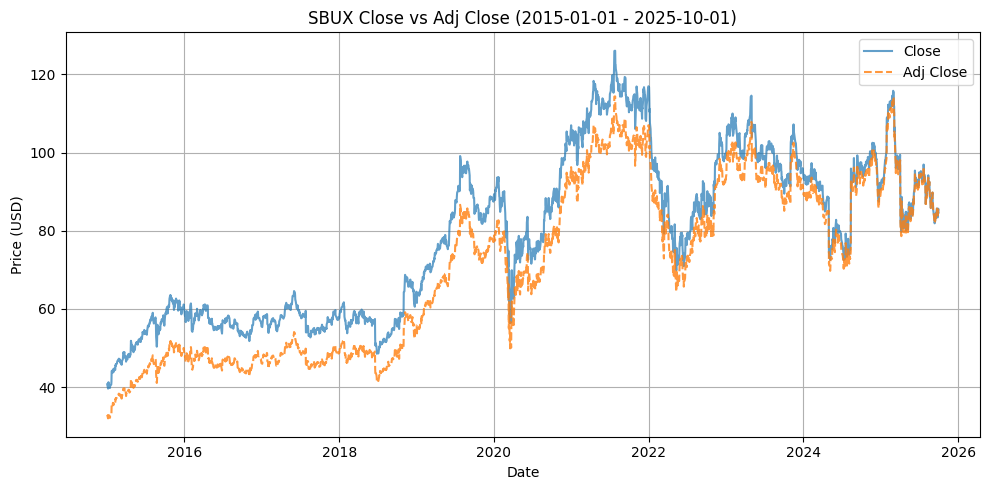

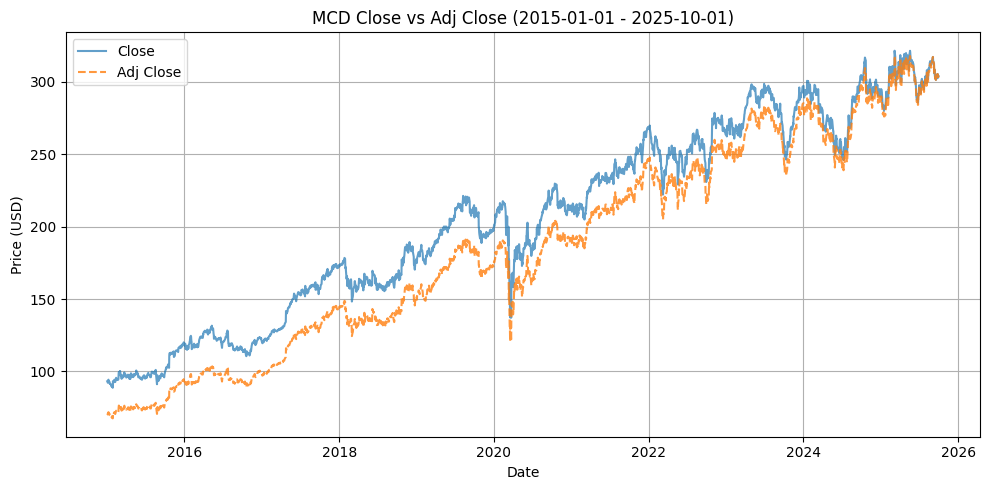

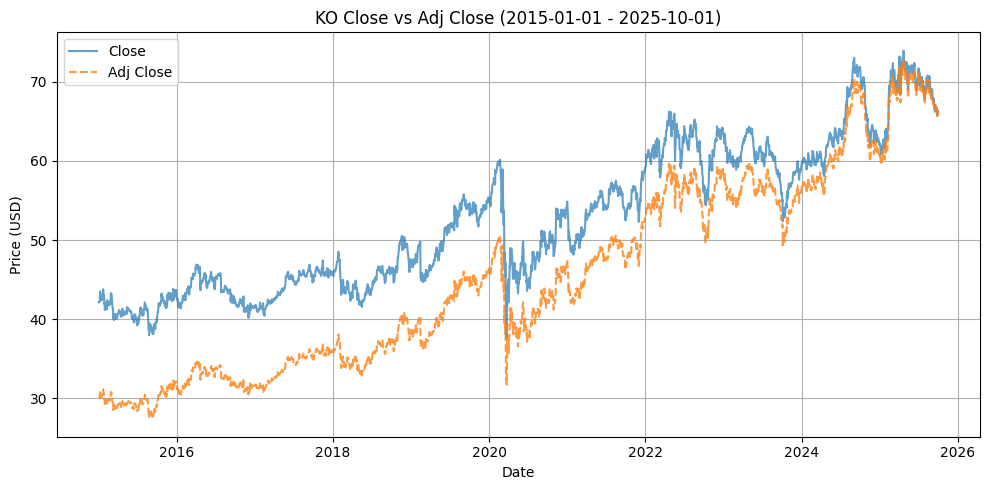

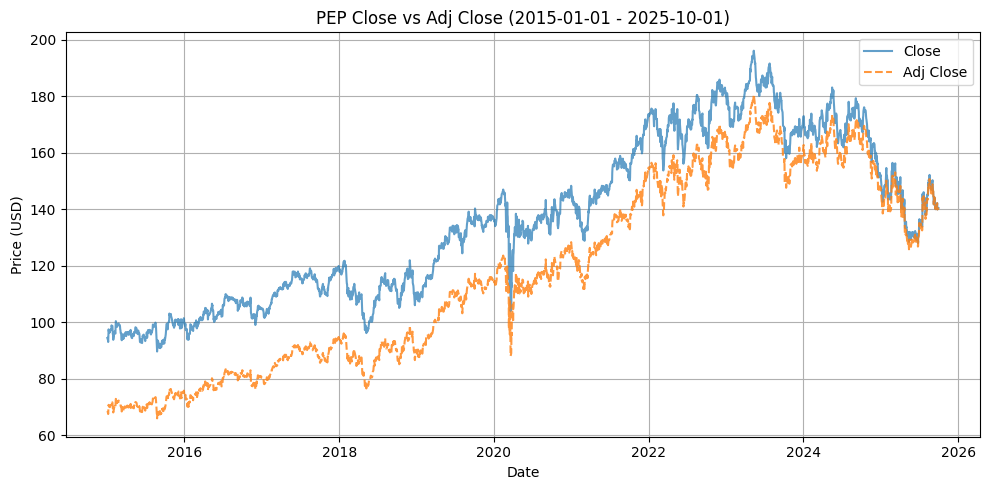

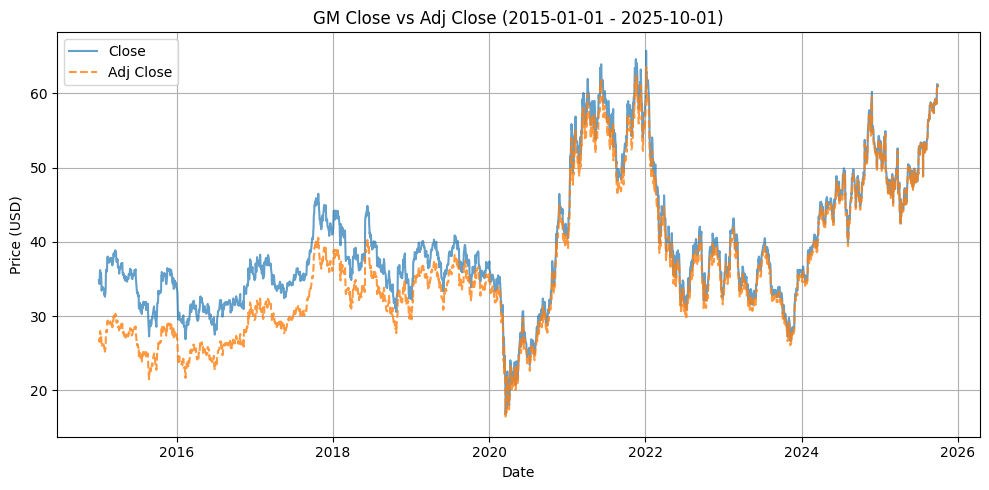

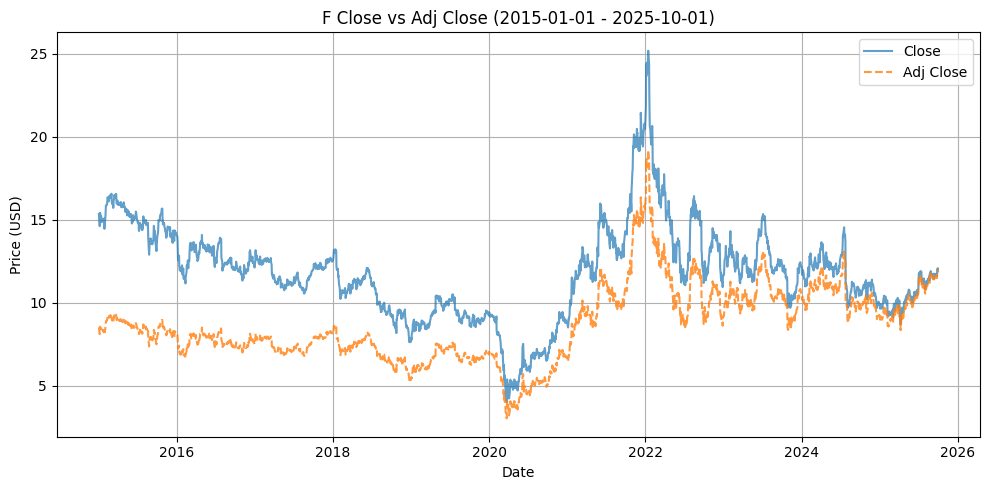

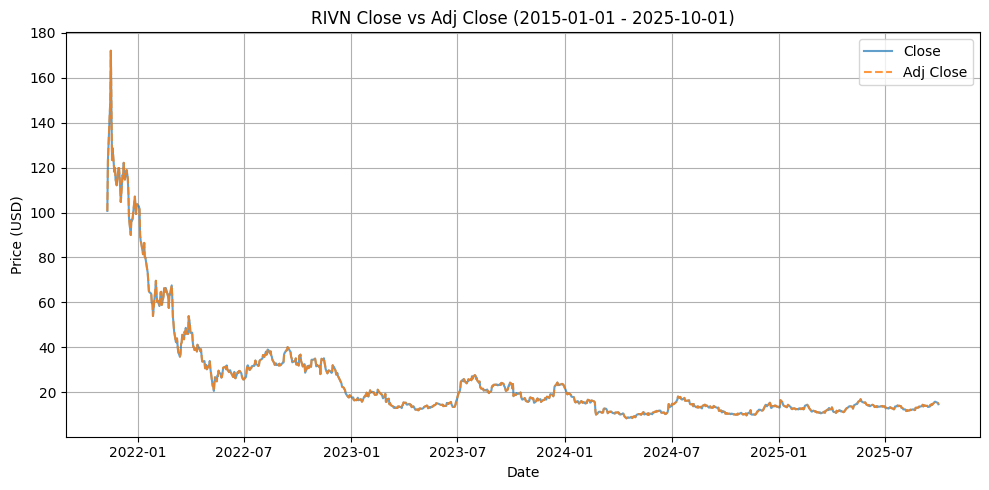

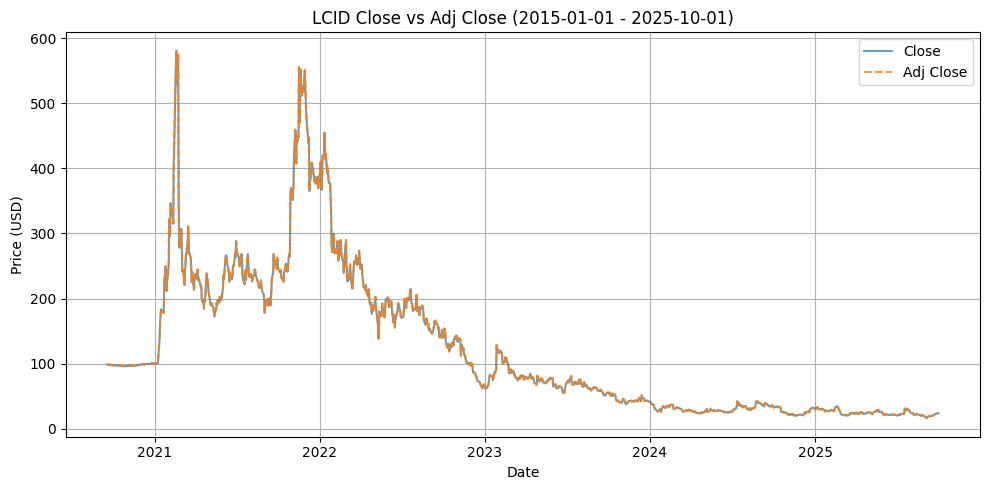

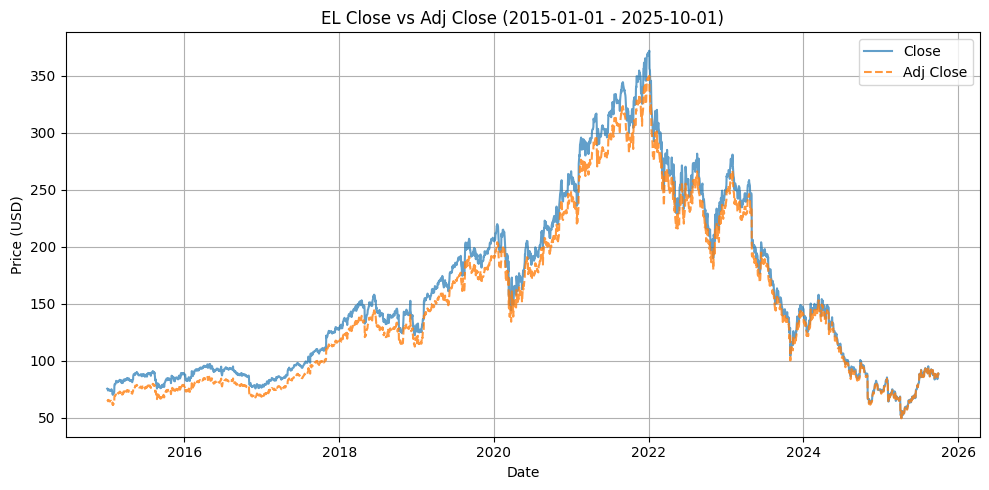

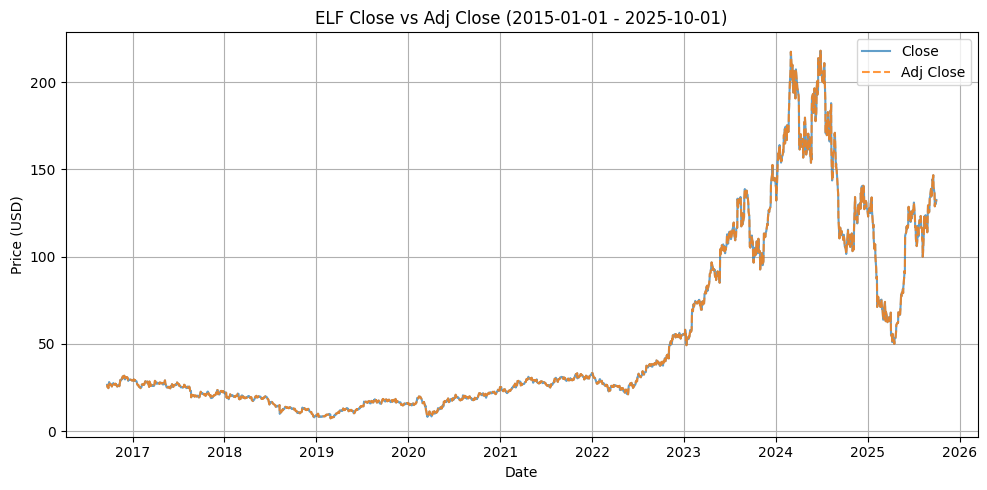

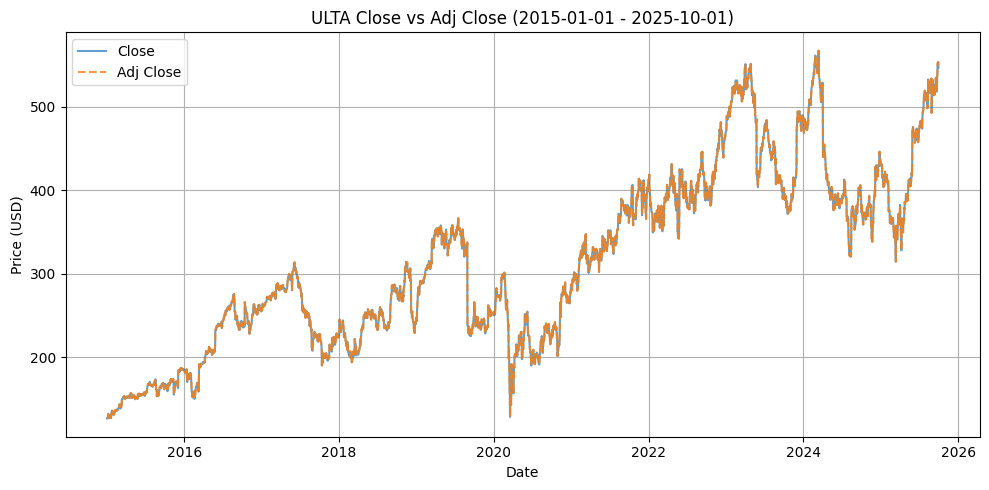

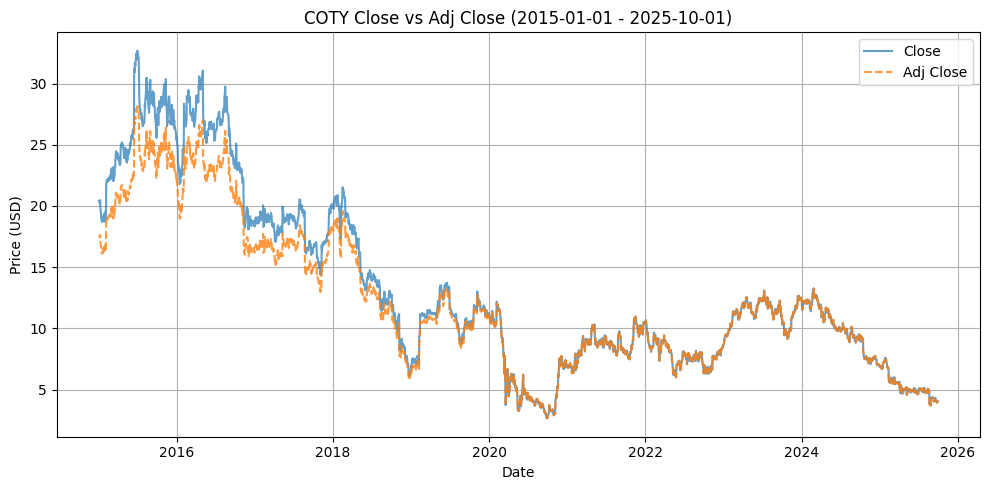

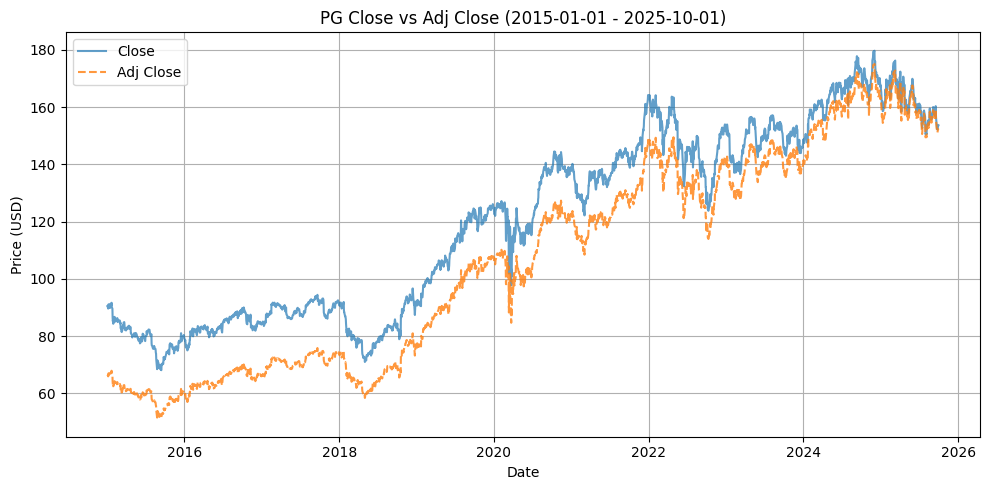

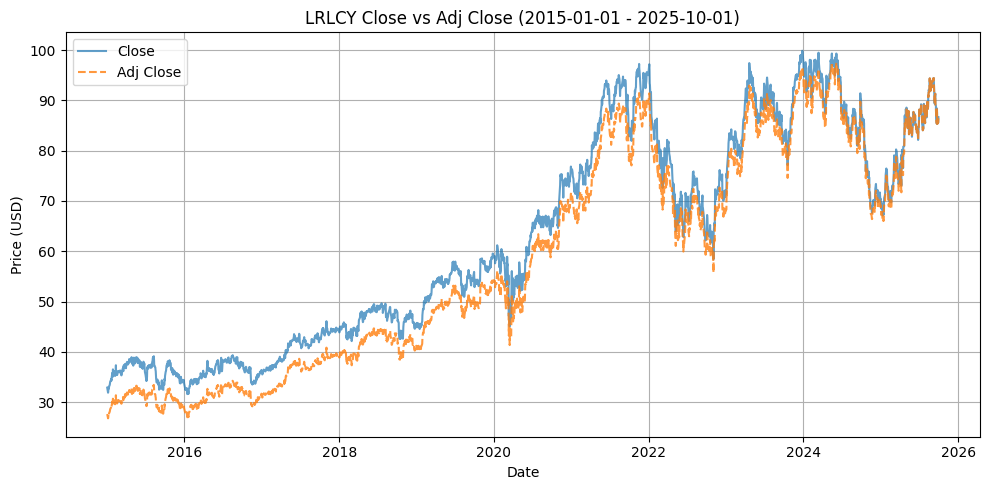

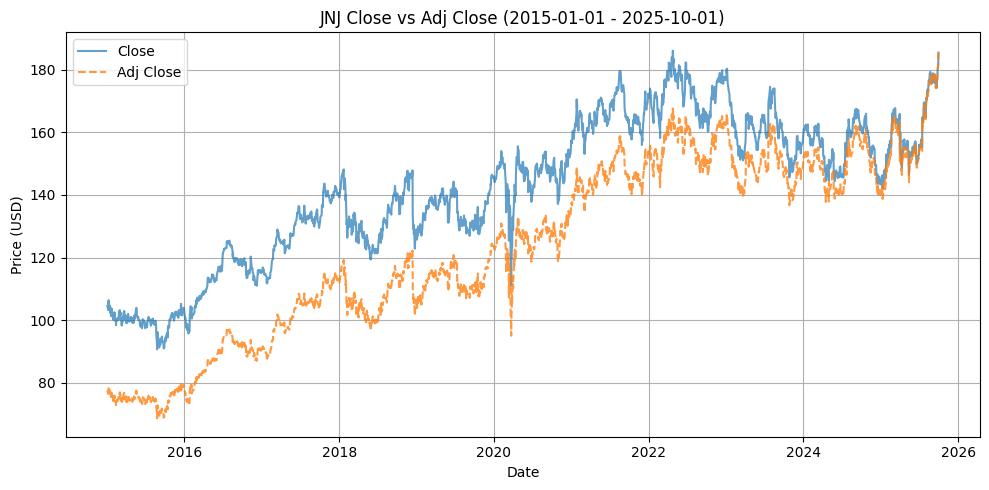

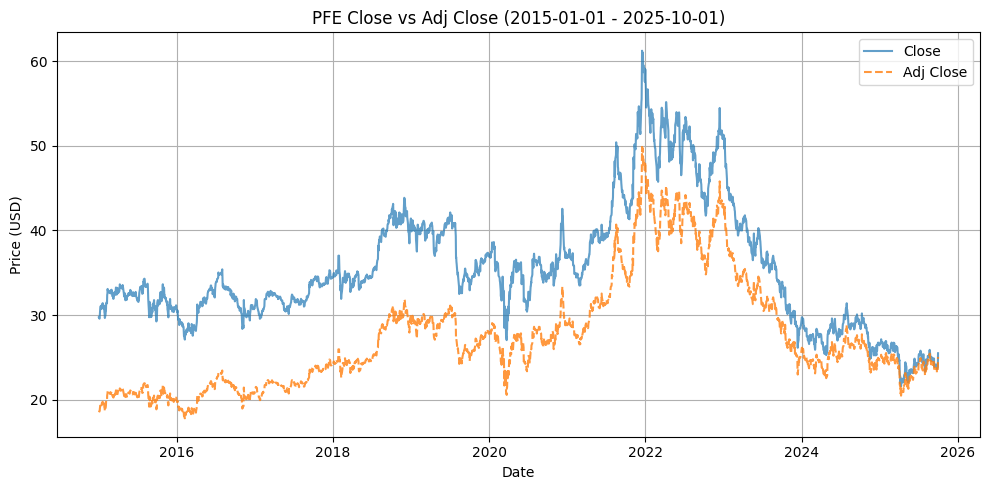

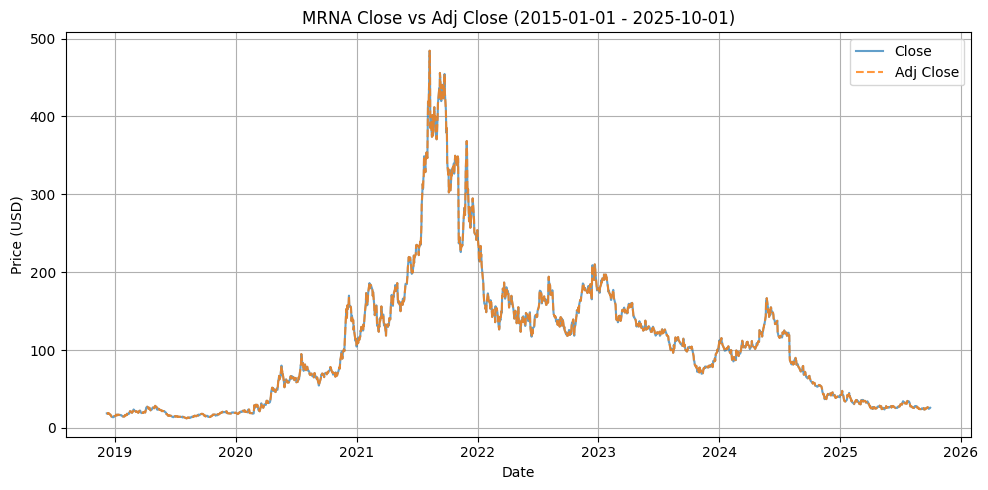

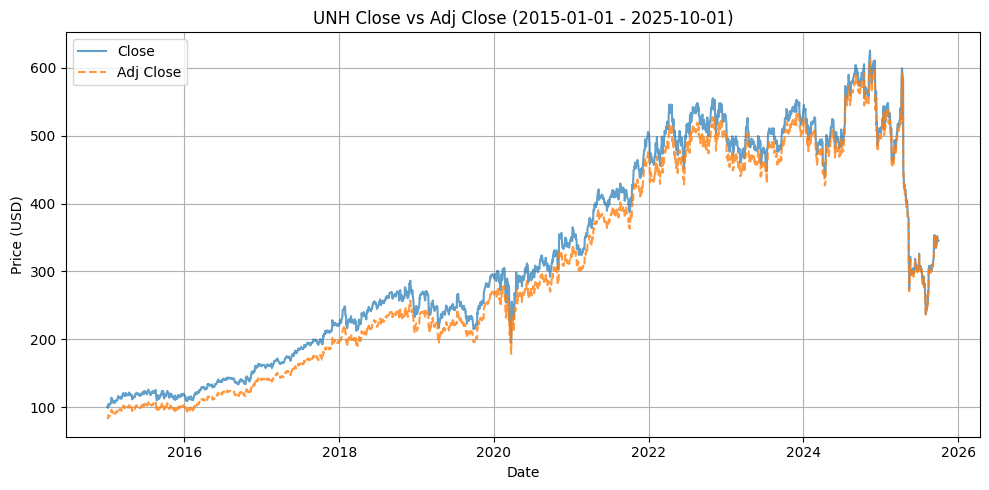

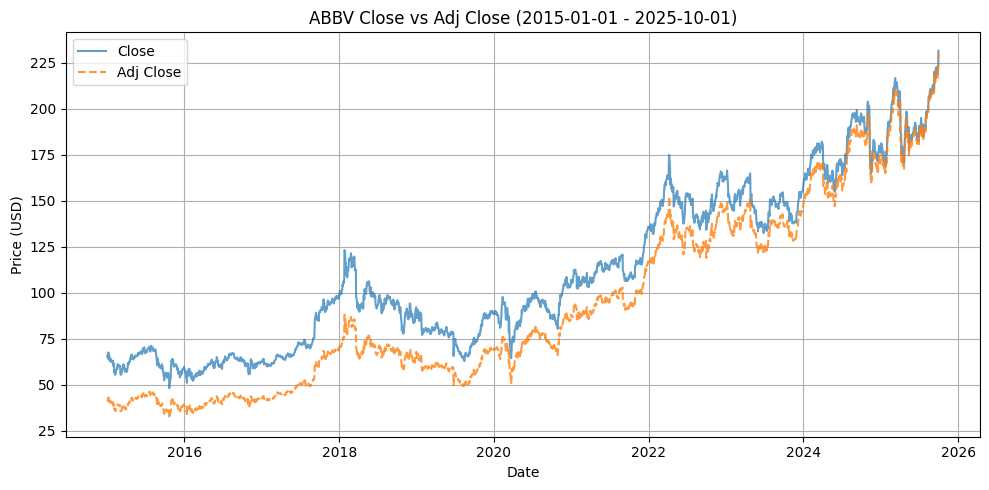

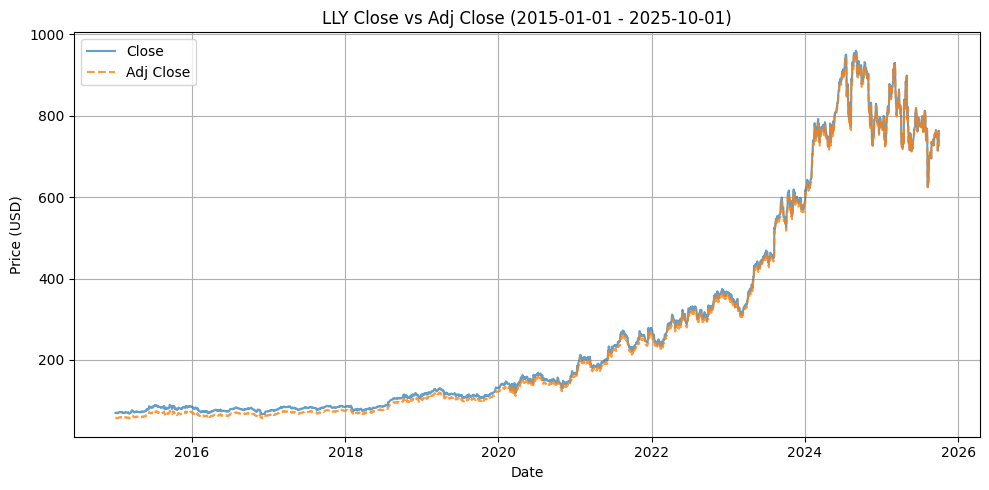

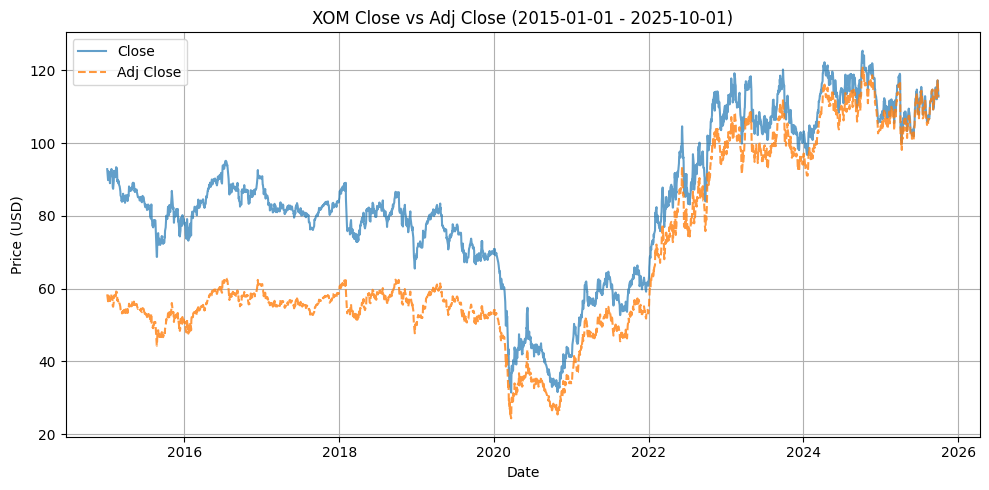

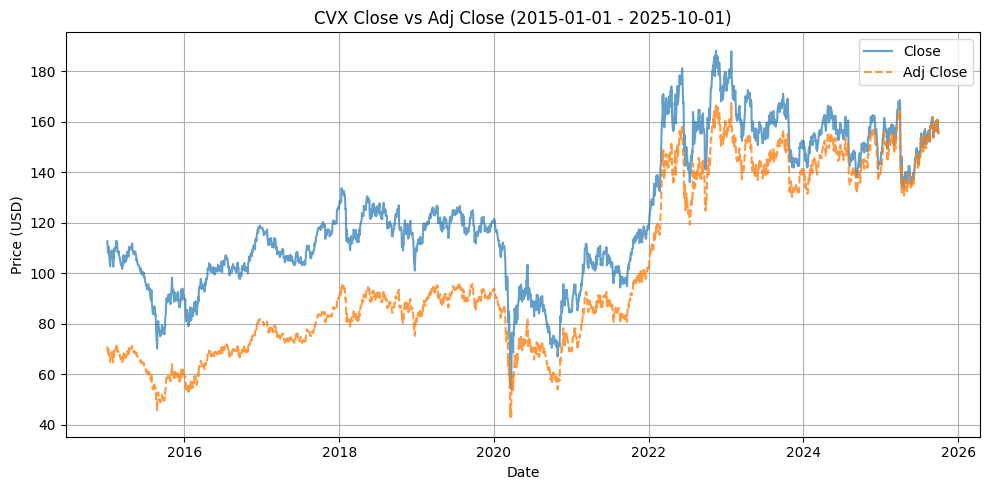

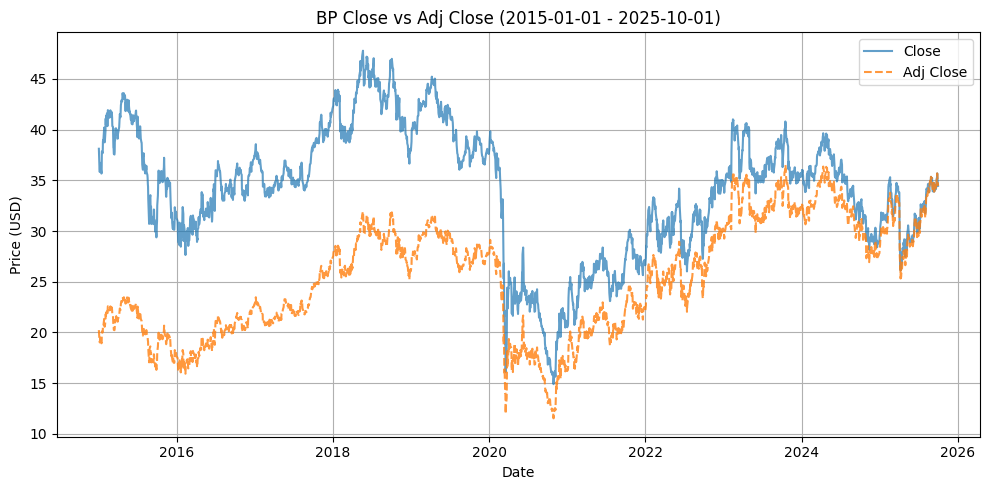

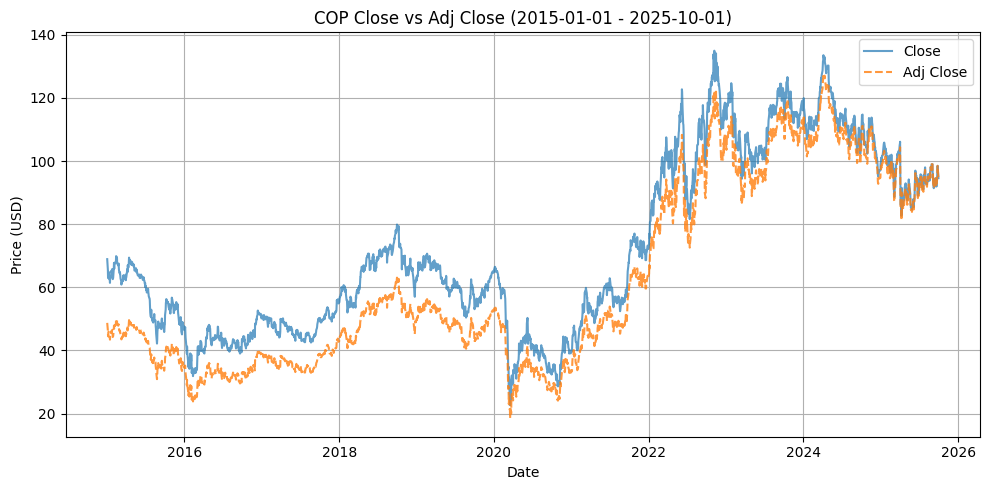

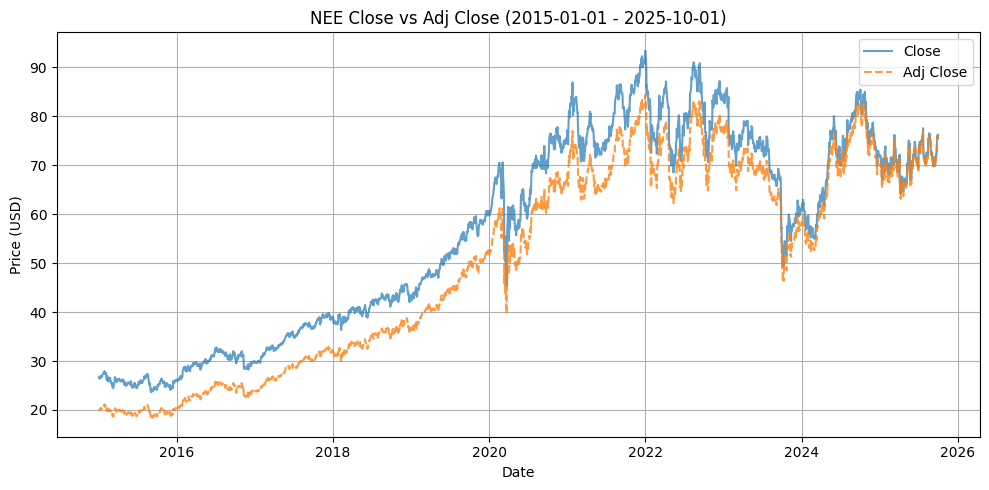

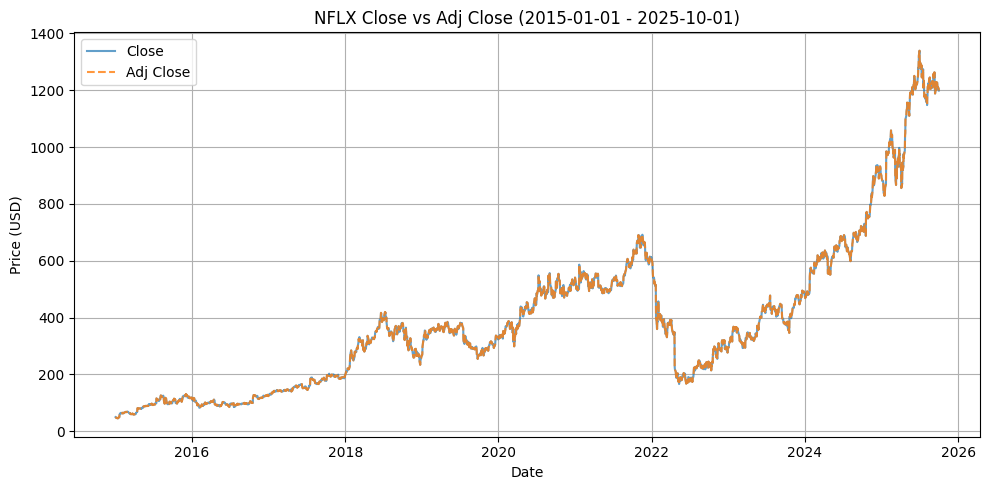

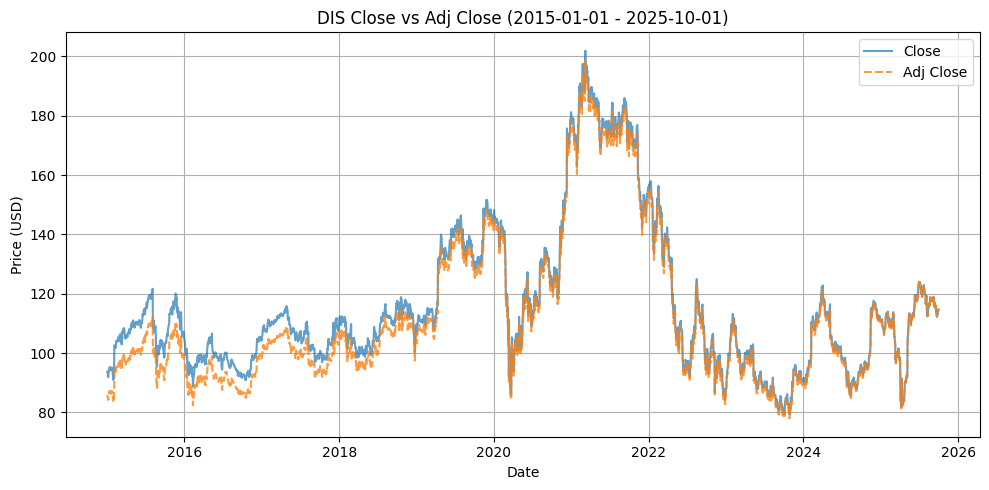

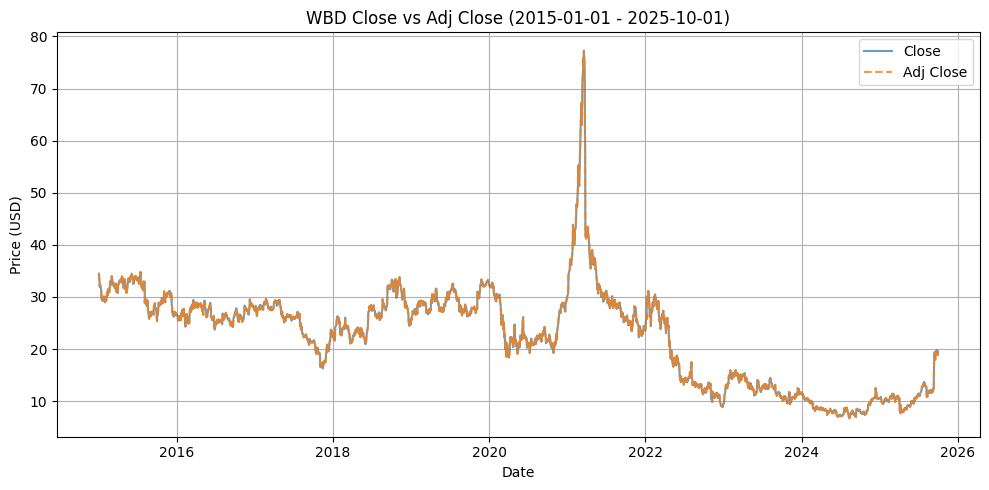

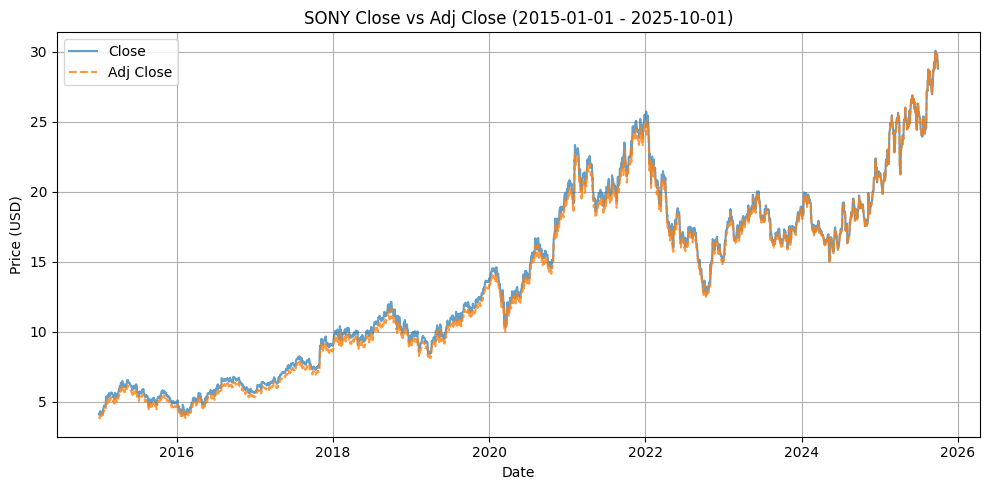

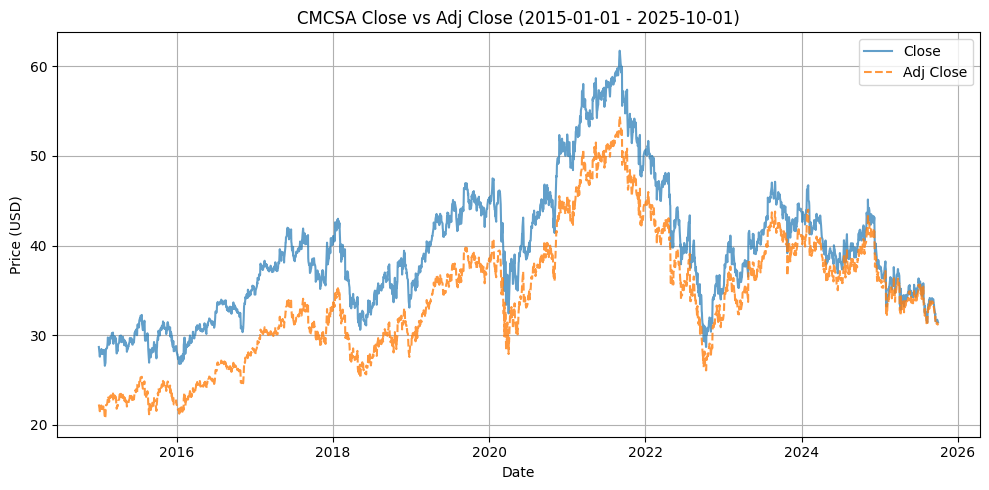

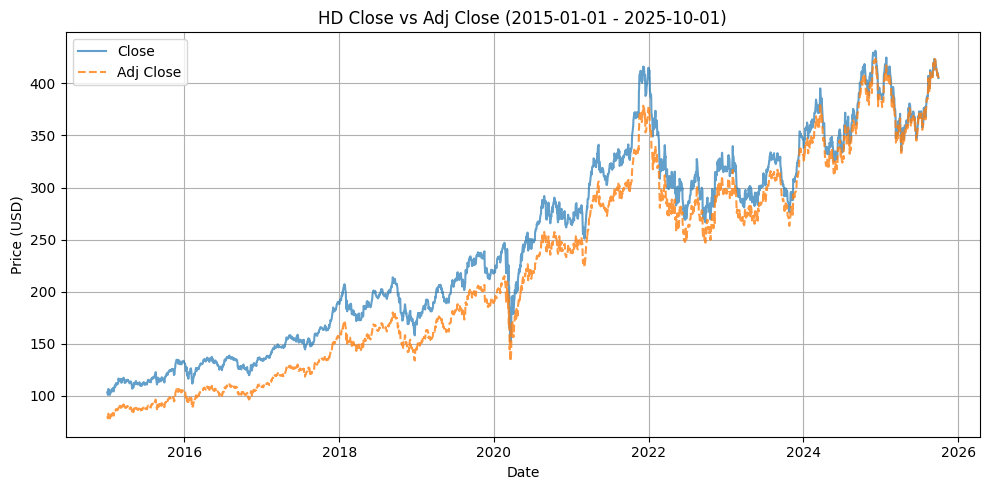

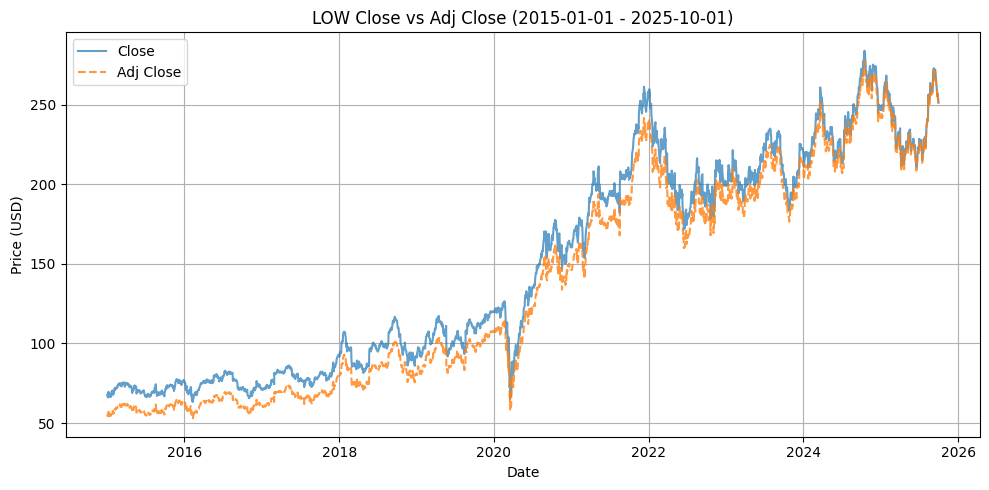

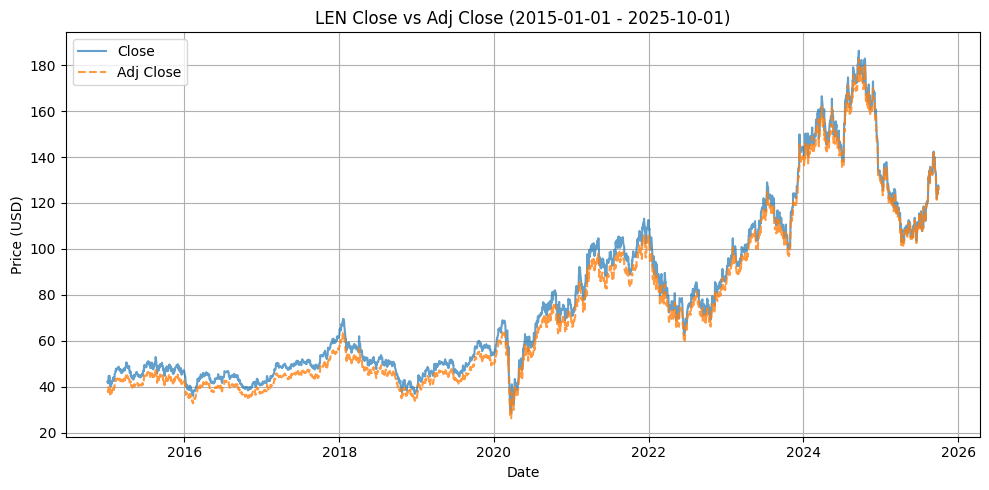

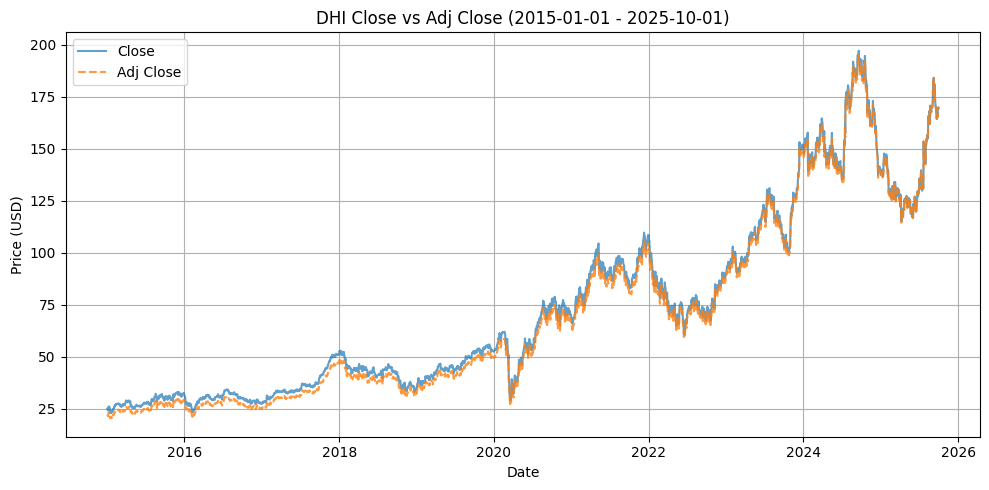

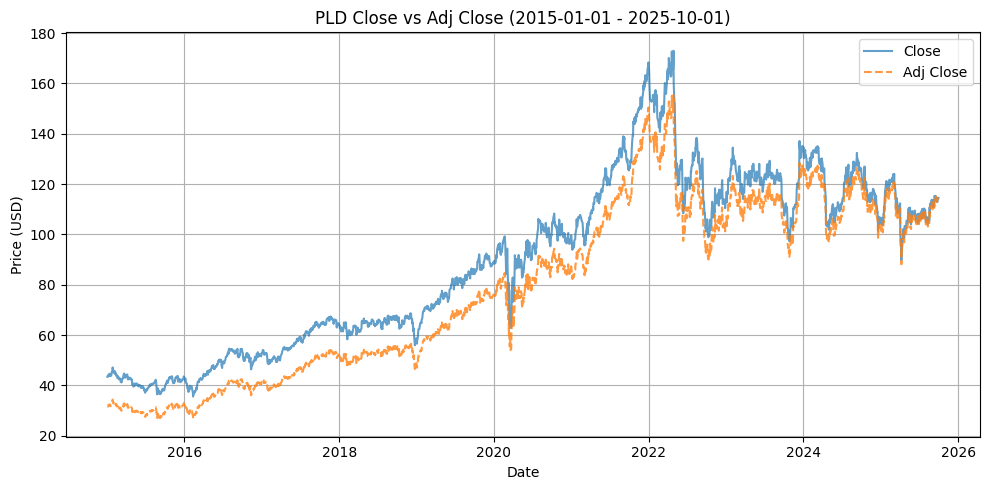

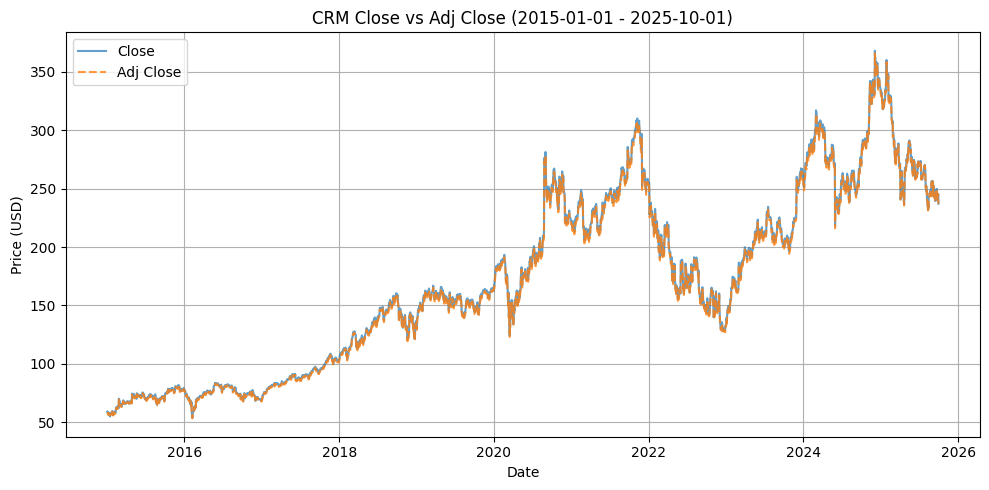

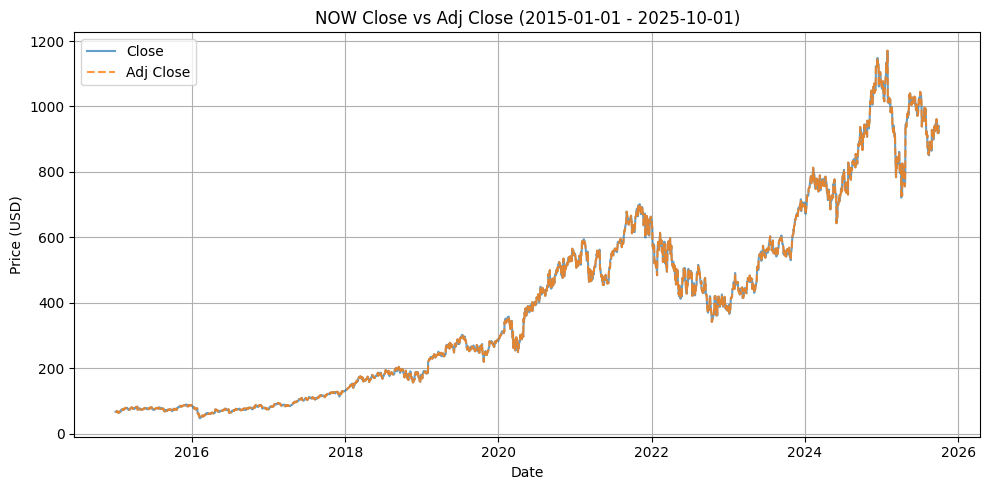

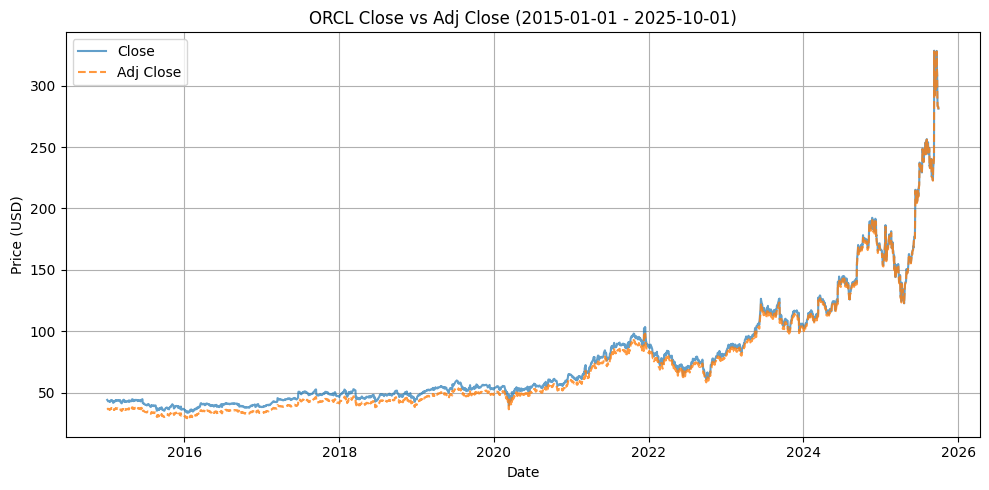

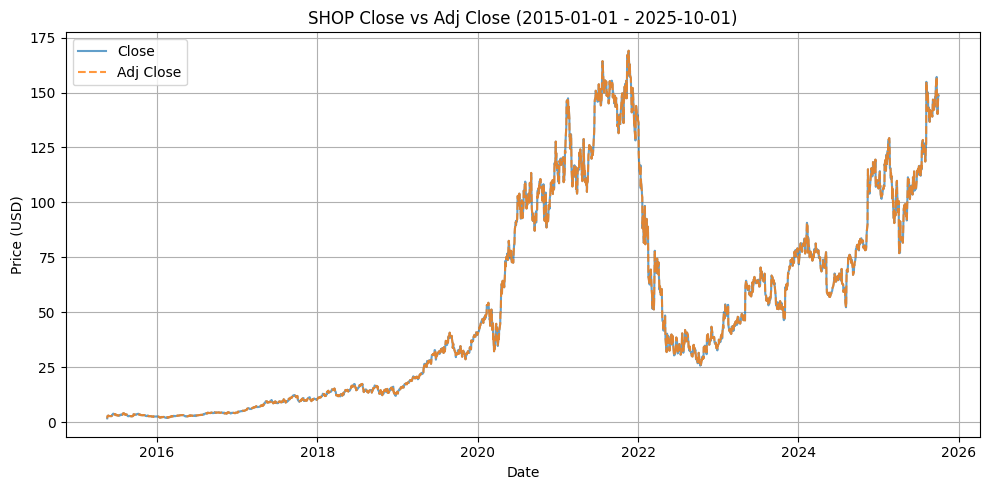

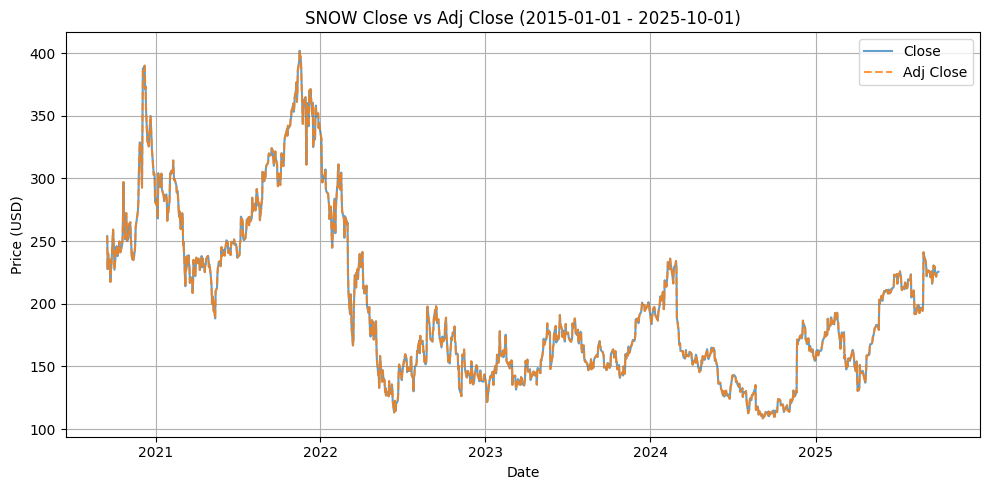

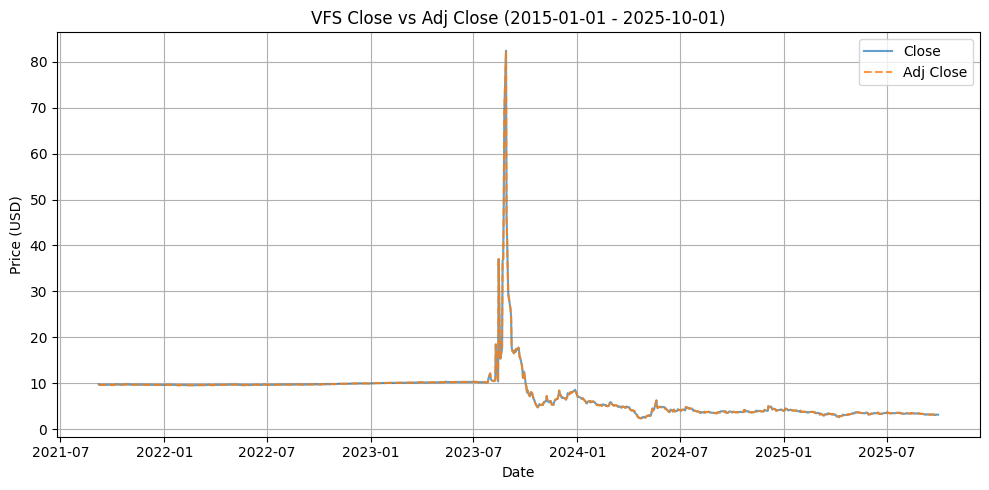

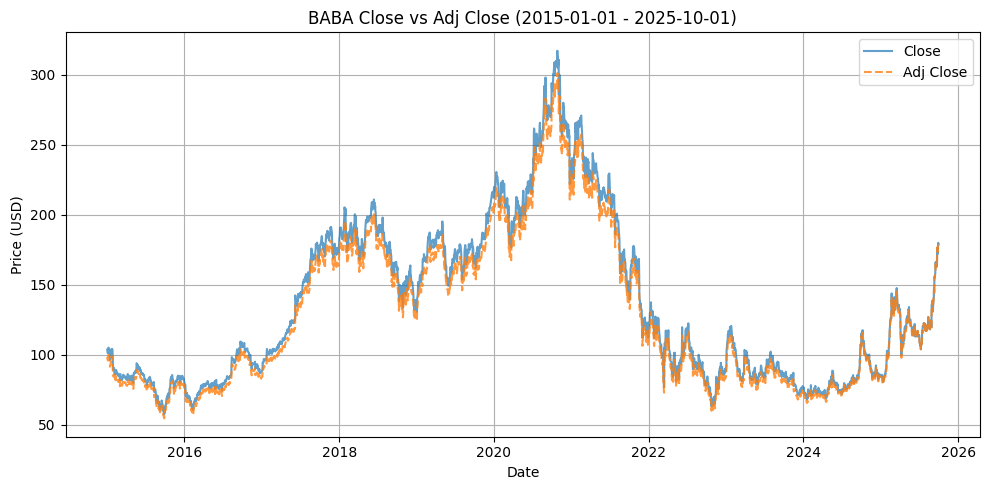

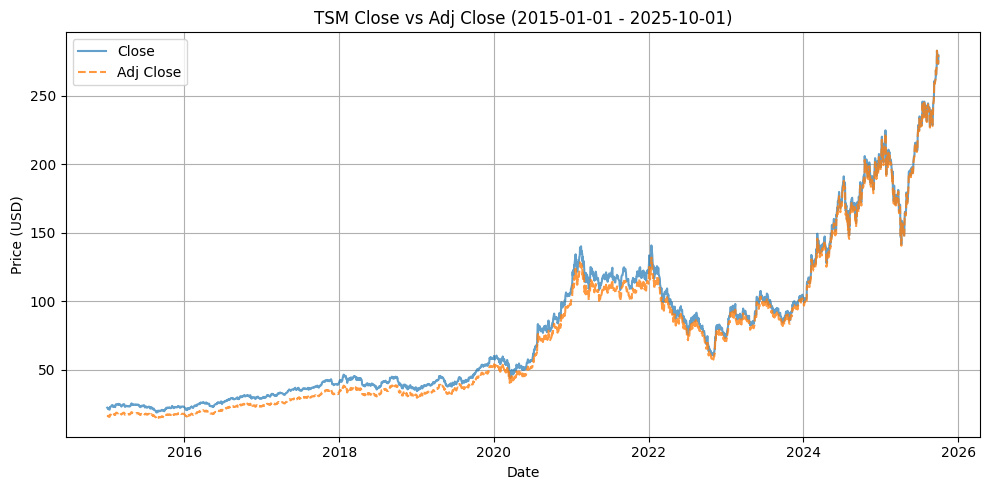

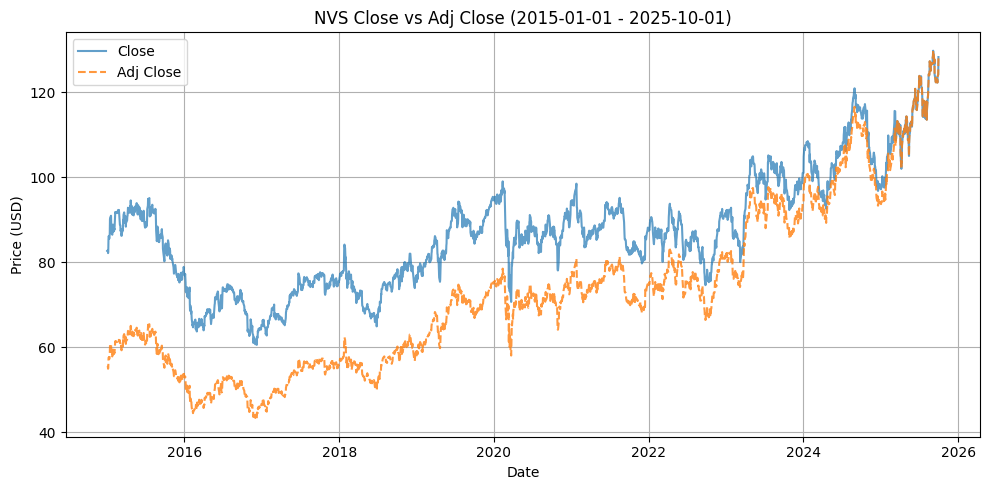

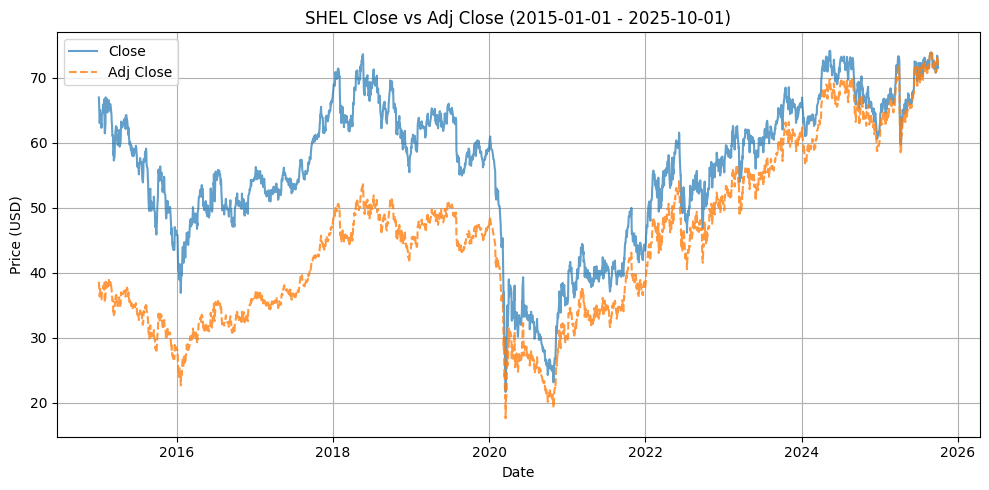

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
import os

# Tạo thư mục lưu hình nếu chưa có
os.makedirs("Stock_Plots", exist_ok=True)

# Danh sách mã cổ phiếu
symbols = ['AAPL', 'MSFT', 'GOOG', 'META', 'AMZN', 'NVDA', 'TSLA', 'AMD', 'INTC', 'ADBE',
           'JPM', 'BAC', 'GS', 'MS', 'V', 'MA', 'PYPL',
           'WMT', 'TGT', 'COST', 'NKE', 'SBUX', 'MCD', 'KO', 'PEP',
           'GM', 'F', 'RIVN', 'LCID',
           'EL', 'ELF', 'ULTA', 'COTY', 'PG', 'LRLCY',
           'JNJ', 'PFE', 'MRNA', 'UNH', 'ABBV', 'LLY',
           'XOM', 'CVX', 'BP', 'COP', 'NEE',
           'NFLX', 'DIS', 'WBD', 'SONY', 'CMCSA',
           'HD', 'LOW', 'LEN', 'DHI', 'PLD',
           'CRM', 'NOW', 'ORCL', 'SHOP', 'SNOW',
           'VFS', 'BABA', 'TSM', 'NVS', 'SHEL']

start_date = '2015-01-01'
end_date = '2025-10-01'

file_path = "Stocks_MultiSheet_(1_1_2015 to 1_10_2025).xlsx"
summary_data = []

with pd.ExcelWriter(file_path, engine="openpyxl") as writer:
    for sym in symbols:
        df = yf.download(sym, start=start_date, end=end_date, progress=False, auto_adjust=False)

        if not df.empty:
            # Giữ lại cột Adj Close (giá đã điều chỉnh)
            df = df[['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']]

            # Ghi dữ liệu vào sheet riêng
            df.to_excel(writer, sheet_name=sym)

            # Tạo summary cho sheet này
            increase_pct = (df['Adj Close'].iloc[-1] - df['Adj Close'].iloc[0]) / df['Adj Close'].iloc[0] * 100
            summary = {
                'Symbol': sym,
                'Adj Close Mean': df['Adj Close'].mean(),
                'Adj Close Max': df['Adj Close'].max(),
                'Adj Close Min': df['Adj Close'].min(),
                'Adj Close Std': df['Adj Close'].std(),
                'Total Volume': df['Volume'].sum(),
                'Increase (%)': increase_pct
            }
            summary_data.append(summary)

            # Vẽ biểu đồ Close và Adj Close
            plt.figure(figsize=(10,5))
            plt.plot(df.index, df['Close'], label='Close', alpha=0.7)
            plt.plot(df.index, df['Adj Close'], label='Adj Close', linestyle='--', alpha=0.8)
            plt.title(f'{sym} Close vs Adj Close ({start_date} - {end_date})')
            plt.xlabel('Date')
            plt.ylabel('Price (USD)')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()  # Hiển thị trong notebook
            plt.savefig(f'Stock_Plots/{sym}_Close_AdjClose.png')  # Lưu hình
            plt.close()

    # Ghi summary vào sheet tổng hợp
    if summary_data:
        summary_df = pd.DataFrame(summary_data)
        summary_df.to_excel(writer, sheet_name="Summary", index=False)

# Tải file Excel về máy
files.download(file_path)


##  **1. Technical indicators and Design trading strategies using technical indicators**

### **Biến file excel thành data frame**

In [ ]:
# Tạo file csv
# Import file dữ liệu excel đã tạo, chuyển thành file csv
!pip install openpyxl
import pandas as pd
from google.colab import files
import io
from scipy.stats.mstats import winsorize
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [ ]:
uploaded = files.upload()
file_name = next(iter(uploaded)) # Lấy tên file đã upload

Saving Stocks_MultiSheet_(1_1_2015 to 1_10_2025).xlsx to Stocks_MultiSheet_(1_1_2015 to 1_10_2025) (1).xlsx


In [ ]:
# Đọc tất cả các sheets. Kết quả là một dictionary {tên_sheet: DataFrame}
# Nếu bạn dùng files.upload() (byte data), hãy dùng io.BytesIO(uploaded[file_name])
# Nếu bạn dùng Google Drive (đường dẫn), hãy dùng file_name
try:
    if 'uploaded' in locals() or 'uploaded' in globals(): # Kiểm tra xem đã upload file chưa
        xls_dict = pd.read_excel(io.BytesIO(uploaded[file_name]), sheet_name=None)
    else:
        xls_dict = pd.read_excel(file_name, sheet_name=None)
except Exception as e:
    print(f"Lỗi khi đọc file Excel: {e}")
    # Xử lý trường hợp không tìm thấy file nếu dùng Google Drive
    # hoặc file_name không đúng nếu dùng files.upload()
    exit()

# Lặp qua dictionary và lưu từng DataFrame thành file CSV
for sheet_name, df in xls_dict.items():
    # Tên file CSV sẽ là tên sheet (mã cổ phiếu)
    csv_file_name = f'{sheet_name}.csv'

    # Sử dụng .to_csv để xuất DataFrame thành file CSV
    # index=False để không bao gồm chỉ mục (index) của DataFrame vào file CSV
    df.to_csv(csv_file_name, index=False, encoding='utf-8')

In [ ]:
import pandas as pd
import glob

# Đọc tất cả file CSV trong thư mục hiện tại
csv_files = glob.glob("*.csv")

dataframes = {}

for file in csv_files:
    # Lấy tên mã cổ phiếu từ tên file (VD: GOOG.csv -> GOOG)
    ticker = file.split(".")[0]

    # Đọc file, bỏ 2 hàng đầu tiên, và dùng hàng thứ 3 làm header
    df = pd.read_csv(file, skiprows=2, header=0)

    # Đổi tên cột 'Price' -> 'Date' (nếu có)
    if 'Price' in df.columns:
        df.rename(columns={'Price': 'Date'}, inplace=True)

    # Lưu DataFrame vào dictionary
    dataframes[ticker] = df

In [ ]:
import pandas as pd
import glob

csv_files = glob.glob("*.csv")
dataframes = {}

for file in csv_files:
    ticker = file.split(".")[0]

    # Đọc file, bỏ 3 hàng đầu (Price, Ticker, header trống)
    df = pd.read_csv(file, skiprows=3, header=None)

    # Tự đặt lại header chuẩn
    df.columns = ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

    # Lưu lại vào dict
    dataframes[ticker] = df

# ✅ Kiểm tra
print(dataframes["GOOG"].head())

                  Date       Open       High        Low      Close  Adj Close  \
0  2015-01-02 00:00:00  26.378078  26.490770  26.133251  26.168653  25.990791   
1  2015-01-05 00:00:00  26.091366  26.144720  25.582764  25.623152  25.448999   
2  2015-01-06 00:00:00  25.679497  25.738087  24.983908  25.029282  24.859165   
3  2015-01-07 00:00:00  25.280592  25.292759  24.914099  24.986401  24.816572   
4  2015-01-08 00:00:00  24.831326  25.105074  24.482782  25.065184  24.894823   

     Volume  
0  28951268  
1  41196796  
2  57998800  
3  41301082  
4  67071641  


### **1. Simple Moving Averages:** (Technical Indicators)
- Khi đường trung bình ngắn hạn (MA ngắn) vượt lên đường trung bình dài hạn (MA dài) $⇒$ xu hướng tăng $⇒$ MUA.
- Khi MA ngắn hạn cắt xuống MA dài hạn $⇒$ xu hướng giảm $⇒$ BÁN.

**VD:** MA ngắn (ví dụ 20 ngày) phản ứng nhanh với giá hiện tại.

MA dài (ví dụ 50 ngày) phản ứng chậm hơn.

Khi MA ngắn vượt MA dài, chứng tỏ giá đang tăng nhanh hơn xu hướng trung bình => tín hiệu mua (golden cross).

Khi ngược lại, ta có bán (death cross)

In [ ]:
# Tạo 1 data frame copy
df_copy = dataframes.copy()
# In thử 1 mã cổ phiếu để kiểm tra
df_copy["AAPL"]

,Date,Open,High,Low,Close,Adj Close,Volume
0,2015-01-02 00:00:00,27.847500,27.860001,26.837500,27.332500,24.261040,212818400
1,2015-01-05 00:00:00,27.072500,27.162500,26.352501,26.562500,23.577568,257142000
2,2015-01-06 00:00:00,26.635000,26.857500,26.157499,26.565001,23.579798,263188400
3,2015-01-07 00:00:00,26.799999,27.049999,26.674999,26.937500,23.910437,160423600
4,2015-01-08 00:00:00,27.307501,28.037500,27.174999,27.972500,24.829132,237458000
...,...,...,...,...,...,...,...
2697,2025-09-24 00:00:00,255.220001,255.740005,251.039993,252.309998,252.309998,42303700
2698,2025-09-25 00:00:00,253.210007,257.170013,251.710007,256.869995,256.869995,55202100
2699,2025-09-26 00:00:00,254.100006,257.600006,253.779999,255.460007,255.460007,46076300
2700,2025-09-29 00:00:00,254.559998,255.000000,253.009995,254.429993,254.429993,40127700


In [ ]:
# Tính SMA của các mã cổ phiếu
for ticker, df in df_copy.items():

    # 1.1. Chuẩn hóa Index và Kiểu Dữ liệu
    if 'Date' in df.columns:

        df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

        # Loại bỏ các hàng mà cột 'Date' là NaT (chứa mã cổ phiếu hoặc dữ liệu rác)
        df.dropna(subset=['Date'], inplace=True)

        # Đặt cột 'Date' đã được làm sạch làm Index
        df = df.set_index('Date')

    # 1.2. Chuyển các cột giá trị sang kiểu số
    df['Adj Close'] = pd.to_numeric(df['Adj Close'], errors='coerce')
    df['Volume'] = pd.to_numeric(df['Volume'], errors='coerce')

    # Loại bỏ các hàng có NaN nếu Adj Close không hợp lệ
    df.dropna(subset=['Adj Close'], inplace=True)

    # 1.3. Tính toán SMA
    df['SMA_20'] = df['Adj Close'].rolling(window=20).mean()
    df['SMA_50'] = df['Adj Close'].rolling(window=50).mean()

    # 1.4. Cập nhật lại DataFrame đã tính toán vào dictionary
    df_copy[ticker] = df

/tmp/ipython-input-2769183352.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(df['Date'], errors='coerce')


In [ ]:
df_copy

{'UNH':                   Open        High         Low       Close   Adj Close  \
 Date                                                                     
 2015-01-02  101.500000  102.620003  100.010002  100.779999   85.048477   
 2015-01-05  100.300003  100.449997   98.750000   99.120003   83.647636   
 2015-01-06   99.830002  100.139999   98.459999   98.919998   83.478828   
 2015-01-07   98.959999  100.300003   98.919998   99.930000   84.331184   
 2015-01-08  101.570000  104.980003  100.720001  104.699997   88.356575   
 ...                ...         ...         ...         ...         ...   
 2025-09-24  350.200012  354.500000  347.839996  351.809998  351.809998   
 2025-09-25  348.899994  350.190002  343.600006  345.559998  345.559998   
 2025-09-26  347.929993  349.970001  341.299988  344.079987  344.079987   
 2025-09-29  343.980011  345.549988  341.450012  345.179993  345.179993   
 2025-09-30  343.750000  349.320007  342.329987  345.299988  345.299988   
 
              Vo

### **2. Upper/Lower Bollinger Band** (Technical Indicators)
- Upper Band = SMA + 2$\sigma$

- Lower Band = SMA -2$\sigma$
- Khi giá cao quá Upper Band, giá cao bất thường.
Khi giá thấp quá Lower band, giá thấp bất thường.

Dựa vào indicator này, có thể xây dựng được cái tín hiệu **Mean Reversion** hoặc **Breakout** tùy ngữ cảnh.

**1.1 Mean Reversion**

- Buy (Mua) khi giá đóng cửa < Lower Band → kỳ vọng bật lên.

- Sell (Bán) khi giá đóng cửa > Upper Band → kỳ vọng điều chỉnh xuống.

- Thoát lệnh khi giá quay lại vùng MA (hoặc MA ± 0.5σ).

**1.2 Breakout**

- Buy khi giá đóng cửa > Upper Band → breakout lên.

- Sell khi giá đóng cửa < Lower Band → breakout xuống.

- Thoát lệnh khi giá quay lại trong dải.

In [ ]:
# Tính Bollinger Band của các mã cổ phiếu
for ticker, df in df_copy.items():

    # 1.1. Tính toán độ lệch chuẩn
    df['STD_20'] = df['Adj Close'].rolling(window=20).std()
    df['STD_50'] = df['Adj Close'].rolling(window=50).std()

    # 1.2. Tính Upper Band và Lower Band
    df['UpperBand_20'] = df['SMA_20'] + 2 * df['STD_20']
    df['LowerBand_20'] = df['SMA_20'] - 2 * df['STD_20']

    df['UpperBand_50'] = df['SMA_50'] + 2 * df['STD_50']
    df['LowerBand_50'] = df['SMA_50'] - 2 * df['STD_50']
    # 1.3. Cập nhật lại DataFrame đã tính toán vào dictionary
    df_copy[ticker] = df

In [ ]:
df_copy['AAPL']

,Open,High,Low,Close,Adj Close,Volume,SMA_20,SMA_50,STD_20,STD_50,UpperBand_20,LowerBand_20,UpperBand_50,LowerBand_50
Date,,,,,,,,,,,,,,
2015-01-02,27.847500,27.860001,26.837500,27.332500,24.261040,212818400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-05,27.072500,27.162500,26.352501,26.562500,23.577568,257142000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-06,26.635000,26.857500,26.157499,26.565001,23.579798,263188400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-07,26.799999,27.049999,26.674999,26.937500,23.910437,160423600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-08,27.307501,28.037500,27.174999,27.972500,24.829132,237458000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-09-24,255.220001,255.740005,251.039993,252.309998,252.309998,42303700,238.300500,226.521144,8.181692,13.472069,254.663883,221.937116,253.465282,199.577006
2025-09-25,253.210007,257.170013,251.710007,256.869995,256.869995,55202100,239.619499,227.460109,8.946886,13.920156,257.513272,221.725727,255.300420,199.619797
2025-09-26,254.100006,257.600006,253.779999,255.460007,255.460007,46076300,240.764500,228.373670,9.447231,14.231692,259.658961,221.870038,256.837055,199.910286


### **3. Log Return**
- Lợi suất Logarit có tính cộng gộp tuyệt đối. Tổng lợi suất Logarit của nhiều kỳ chính là logarit của giá cuối cùng chia cho giá ban đầu.

- Việc cộng dồn Log Returns rất thuận tiện cho việc tính toán hiệu suất tích lũy dài hạn và mô hình hóa chuỗi thời gian, vì bạn có thể cộng chúng lại để tìm tổng lợi suất của một danh mục đầu tư. (để phù hợp dữ liệu Time Series ở Lab 05).
- Nhiều mô hình thống kê (bao gồm Hồi quy ) hoạt động tốt nhất khi dữ liệu đầu vào tuân theo Phân phối Chuẩn (Normal Distribution). Mà do tính cộng gộp, $\log(p_{t})$ có xu hướng phân phối chuẩn (tức là $p_{t}$ có xu hướng phân phối Log-Normal). Làm cho các kiểm định thống kê và mô hình hóa trở nên đáng tin cậy hơn.
- Đảm bảo rằng các kiểm định xác thực mô hình hồi quy (ví dụ: Breusch-Pagan Test) trở nên đáng tin cậy hơn.

In [ ]:
# Tính log return của mỗi mã cổ phiếu
import numpy as np

for ticker, df in dataframes.items():

    # 1.1 Tính Log Returns (Lợi suất Logarit)
    df['Log_Returns'] = np.log(df['Adj Close'] / df['Adj Close'].shift(1))
    # 1.2 Cập nhật lại DataFrame đã tính toán vào dictionary
    df_copy[ticker] = df

In [ ]:
# In để kiểm tra
df_copy['AAPL']

,Date,Open,High,Low,Close,Adj Close,Volume,Log_Returns
0,2015-01-02,27.847500,27.860001,26.837500,27.332500,24.261040,212818400,NaN
1,2015-01-05,27.072500,27.162500,26.352501,26.562500,23.577568,257142000,-0.028576
2,2015-01-06,26.635000,26.857500,26.157499,26.565001,23.579798,263188400,0.000095
3,2015-01-07,26.799999,27.049999,26.674999,26.937500,23.910437,160423600,0.013925
4,2015-01-08,27.307501,28.037500,27.174999,27.972500,24.829132,237458000,0.037703
...,...,...,...,...,...,...,...,...
2697,2025-09-24,255.220001,255.740005,251.039993,252.309998,252.309998,42303700,-0.008367
2698,2025-09-25,253.210007,257.170013,251.710007,256.869995,256.869995,55202100,0.017912
2699,2025-09-26,254.100006,257.600006,253.779999,255.460007,255.460007,46076300,-0.005504
2700,2025-09-29,254.559998,255.000000,253.009995,254.429993,254.429993,40127700,-0.004040


### **4. Volatility**
- Độ lệch chuẩn ($\sigma$) của Log Returns trong một cửa sổ cố định (ví dụ: 20 hoặc 50 ngày).
- Dùng để đo rủi ro và là thành phần quan trọng trong Bollinger Bands. (đã tính ở phần 2)

### **5. Turnover**
Doanh số phản ánh giá trị tiền tệ thực tế được giao dịch, giúp so sánh hoạt động giao dịch công bằng hơn giữa các công ty (quan trọng khi xử lý Thinly Traded Stocks - Cổ phiếu giao dịch thưa thớt) (Ở lab 04).

In [ ]:
# Tính doanh số Turnover = Volumn * Close
import numpy as np

for ticker, df in dataframes.items():

    # 1.1 Tính doanh số TurnOver
    df['Turnover'] = df['Volume']*df['Close']
    # 1.2 Cập nhật lại DataFrame đã tính toán vào dictionary
    df_copy[ticker] = df

In [ ]:
# In để kiểm tra
df_copy['AAPL']

,Date,Open,High,Low,Close,Adj Close,Volume,Log_Returns,Turnover
0,2015-01-02,27.847500,27.860001,26.837500,27.332500,24.261040,212818400,NaN,5.816859e+09
1,2015-01-05,27.072500,27.162500,26.352501,26.562500,23.577568,257142000,-0.028576,6.830334e+09
2,2015-01-06,26.635000,26.857500,26.157499,26.565001,23.579798,263188400,0.000095,6.991600e+09
3,2015-01-07,26.799999,27.049999,26.674999,26.937500,23.910437,160423600,0.013925,4.321411e+09
4,2015-01-08,27.307501,28.037500,27.174999,27.972500,24.829132,237458000,0.037703,6.642294e+09
...,...,...,...,...,...,...,...,...,...
2697,2025-09-24,255.220001,255.740005,251.039993,252.309998,252.309998,42303700,-0.008367,1.067365e+10
2698,2025-09-25,253.210007,257.170013,251.710007,256.869995,256.869995,55202100,0.017912,1.417976e+10
2699,2025-09-26,254.100006,257.600006,253.779999,255.460007,255.460007,46076300,-0.005504,1.177065e+10
2700,2025-09-29,254.559998,255.000000,253.009995,254.429993,254.429993,40127700,-0.004040,1.020969e+10


## **2. Design momentum strategies using price-volume data**

### **Momentum tích lũy (Cumulative Momentum)**
- Thay vì chỉ xét một bước thay đổi của 1 khoảng thời gian ngắn, ta cộng dồn (tích lũy) momentum qua thời gian để đo độ mạnh liên tục của xu hướng.

=> Có thể coi như là tổng hiệu suất liên tục của giá trong một khoảng cửa sổ trượt (rolling window).

**Momentum theo hướng xu hướng** (trend-following): Giá có đà tăng mạnh → tiếp tục mua; đà giảm mạnh → tiếp tục bán.
- Khi CumMomentum > ngưỡng dương → xu hướng tăng → Tín hiệu buy

- Khi CumMomentum < ngưỡng âm → xu hướng giảm → Tín hiệu sell

**Momentum đảo chiều** (mean reversion):
Động lượng tích lũy quá lớn thì sắp đảo chiều.
- Khi CumMomentum quá cao → thị trường quá nóng → Bán

- Khi CumMomentum quá thấp → thị trường quá nguội → Mua

### **Nguyên tắc cơ bản**

- Window (số ngày tích lũy) càng ngắn → tín hiệu nhạy hơn, nhưng nhiễu hơn.

- Window càng dài → tín hiệu ổn định hơn, nhưng chậm phản ứng.

Ta cần chọn sao cho vừa đủ nhạy để bắt xu hướng, không bị nhiễu do dao động nhỏ.
=> Chọn 120 ngày, vừa đủ mạnh mẽ ước lượng thị trường, vừa không quá nhiễu do ít ngày.

In [ ]:
# Tính Momentum tích lũy 120 ngày
for ticker, df in dataframes.items():

    # 1.1 Tính Momentum tích lũy trong 120 ngày từ Log_return đã tính
    df['Momentum_120D'] = df['Log_Returns'].rolling(window=120).sum()

    # 1.2 Gán lại DataFrame vào dictionary
    df_copy[ticker] = df

In [ ]:
# In để kiểm tra
df_copy['AAPL']

,Date,Open,High,Low,Close,Adj Close,Volume,Log_Returns,Turnover,Momentum_120D
0,2015-01-02,27.847500,27.860001,26.837500,27.332500,24.261040,212818400,NaN,5.816859e+09,NaN
1,2015-01-05,27.072500,27.162500,26.352501,26.562500,23.577568,257142000,-0.028576,6.830334e+09,NaN
2,2015-01-06,26.635000,26.857500,26.157499,26.565001,23.579798,263188400,0.000095,6.991600e+09,NaN
3,2015-01-07,26.799999,27.049999,26.674999,26.937500,23.910437,160423600,0.013925,4.321411e+09,NaN
4,2015-01-08,27.307501,28.037500,27.174999,27.972500,24.829132,237458000,0.037703,6.642294e+09,NaN
...,...,...,...,...,...,...,...,...,...,...
2697,2025-09-24,255.220001,255.740005,251.039993,252.309998,252.309998,42303700,-0.008367,1.067365e+10,0.121948
2698,2025-09-25,253.210007,257.170013,251.710007,256.869995,256.869995,55202100,0.017912,1.417976e+10,0.236873
2699,2025-09-26,254.100006,257.600006,253.779999,255.460007,255.460007,46076300,-0.005504,1.177065e+10,0.307049
2700,2025-09-29,254.559998,255.000000,253.009995,254.429993,254.429993,40127700,-0.004040,1.020969e+10,0.340435


In [ ]:
df_copy['AAPL']['Date']

,Date
0,2015-01-02
1,2015-01-05
2,2015-01-06
3,2015-01-07
4,2015-01-08
...,...
2697,2025-09-24
2698,2025-09-25
2699,2025-09-26
2700,2025-09-29


In [ ]:
import pickle
import pandas as pd # Vẫn cần pandas vì các giá trị trong dict là DataFrames

# Đường dẫn mặc định khi file được tải lên
file_path = 'df_copy.pkl'

# Tải lại Dictionary từ file pickle
try:
    with open(file_path, 'rb') as f:
        loaded_dataframes = pickle.load(f)

    # Kiểm tra
    print(f"✅ Đã tải lại thành công {len(loaded_dataframes)} DataFrames.")
    print("Mã cổ phiếu đầu tiên là:", list(loaded_dataframes.keys())[0])

except FileNotFoundError:
    print(f"❌ Lỗi: Không tìm thấy file {file_path}. Hãy kiểm tra lại tên file.")

✅ Đã tải lại thành công 67 DataFrames.
Mã cổ phiếu đầu tiên là: UNH


In [ ]:
loaded_dataframes['AAPL'].head()

,Date,Open,High,Low,Close,Adj Close,Volume,Log_Returns,Turnover,Momentum_120D
0,2015-01-02,27.847500,27.860001,26.837500,27.332500,24.261040,212818400,NaN,5.816859e+09,NaN
1,2015-01-05,27.072500,27.162500,26.352501,26.562500,23.577568,257142000,-0.028576,6.830334e+09,NaN
2,2015-01-06,26.635000,26.857500,26.157499,26.565001,23.579798,263188400,0.000095,6.991600e+09,NaN
3,2015-01-07,26.799999,27.049999,26.674999,26.937500,23.910437,160423600,0.013925,4.321411e+09,NaN
4,2015-01-08,27.307501,28.037500,27.174999,27.972500,24.829132,237458000,0.037703,6.642294e+09,NaN
